# Magic-state cultivation, d = 3: every fault at once

> **In short.**
> * **The problem.** Cultivation makes a T state inside the [[7,1,3]] colour code. A run is thrown away when a check fires. A *fault* is a Pauli error right after one gate, on its qubits: X, Y or Z after a one-qubit gate, or any of the 15 two-qubit Paulis (all but II) after a CNOT. The *fault distance* is the fewest faults that pass every check and still leave a wrong state.
> * **Why this is hard for other tools.** Stim cannot run T gates. zxqec's own `circuit_distance` uses Stim, so it too needs S in place of T (Section 7). Deciding each pattern of faults on the whole circuit is slow: there are 1695420 pairs of faults, about 39 hours that way (Section 6). SyQMA and Tsim do work with T gates; Section 8 says how they differ.
> * **Our way.** Two switches after every gate, on each of its qubits: one for an X, one for a Z. So every Pauli fault after every gate is a value of the switches (Section 3). The switches are pushed to the end with Pauli rules. This gives a formula for each result, each T gate and each output (Section 5). The circuit is reduced once, with the 15 T switches and the output Pauli kept as variables (Section 4). A pattern of faults is then decided from its formulas, plus a small diagram when needed (Section 6).
> * **The answer.** With real T gates, **2 faults** are enough. With S in place of T it is 3 (Section 7).
>   * A solver (`search_lowest_wrong`, Section 7) gives the fault distance. It gives a *witness*: which faults, after which gate, on which qubit. It says why the witness is wrong: the T gates it turns around, and the Pauli it leaves. This takes about 5 s, plus about 7.0 s to build its model.
>   * With `all_wrong=True` it lists every wrong *signature* (what a pattern flips and leaves; Section 5). There are 12, with one pair for each. That takes about 10 s, plus about 5.2 s for its model. Trying every pair (Section 6) finds 48 wrong pairs in about 503 s. They have exactly these 12 signatures.
>   * **Certified:** each wrong pattern found is checked by `classify` and by `classify_directly`. Section 6 tries every single fault and every pair.
>   * **Argued:** that the solver alone misses no lighter wrong pattern and no wrong signature. This rests on three things: the branch argument, the class cut, and the solver's answer "nothing left" (all in Section 7). Here, trying every pair confirms it.
> * **Times.** The load of the machine is printed in the first and the last cell: other programs ran at the same time (among them a long d = 5 run), so the times here are longer than on a quiet machine.

| step | what | function | result |
|---|---|---|---|
| 1 | read the circuit | `program_from_stim`, `draw_program`, `code_at` | 18 qubits, 231 gates, 15 T gates; the [[7,1,3]] code at the end |
| 2 | reduce it, no faults | `reduce_gpf`, `check_detectors`, `in_face_variables`, `code_layout`, `draw_graph_3d`, `draw_slice` | 15 T gadgets become 1 (7π/4); 26 checks; the Steane triangle with $T^\dagger\vert+\rangle$ on L |
| 3 | two switches after every gate | `error_formulas` | 304 places, 608 switches; 15 T switches (sums of switches) |
| 4 | one reduction, every variable kept | `ef.reduced`, `in_face_variables`, `code_layout`, `layout_gpf`, `draw_graph`, `same_map` | 43 spiders, 15 gadgets; drawn as a GPF with names, every phase in a list; the same map (up to a number) for 30 of 30 random values |
| 5 | every equation | `formula`, `detector_switches`, `signature` | 15 T switches, 31 results, 7 outputs; 26 checks |
| 6 | decide faults, fast and slow | `classify`, `classify_directly`, `lowest_wrong` | no single fault is wrong; 48 wrong pairs (about 503 s); the slow way would take about 39 hours |
| 7 | a solver | `branch_model`, `search_lowest_wrong` (sat, coset), `circuit_distance` | 2 with real T, and a witness pair (about 5 s); all 12 wrong signatures, the same as those of the 48 wrong pairs (about 10 s, against about 503 s for every pair); 3 with S in place of T |

Each step below has **What we do** (plain words), the code (library calls only), and **What you see** (from the output). The pictures are also saved in `figures/cultivation_faults/`.

**What we do.** We load the library, zxqec (it uses PyZX). We print where zxqec is read from, so we know which copy runs.

We also print how busy the machine is (its *load*). Other programs that run at the same time make every time in this notebook longer.

In [1]:
%matplotlib inline
import os
import random
import textwrap
import time
from collections import Counter
from IPython.display import display
from pyzx import VertexType
import zxqec
from zxqec.gpf import (boolean_variables, consistent_assignments, equal_for_all_assignments, is_leaf, layout_gpf,
                       phase_polynomial, reduce_gpf, same_map, sample_consistent_assignment)
from zxqec.qprogram import (NotCliffordError, branch_model, check_detectors, circuit_distance, error_formulas,
                            program_from_stim, search_lowest_wrong)
from zxqec.spacetime import (code_layout, draw_checks, draw_graph, draw_graph_3d, draw_program, draw_slice,
                             in_face_variables)
print("zxqec is read from", os.path.dirname(zxqec.__file__))
print("this machine has {} cores; load average now (last 1, 5, 15 minutes): {:.1f}, {:.1f}, {:.1f}".format(
    os.cpu_count(), *os.getloadavg()))
FIG = 'figures/cultivation_faults'
os.makedirs(FIG, exist_ok=True)
start = time.perf_counter()

zxqec is read from /Users/chenxi/Leiden/zx-qec/zxqec/zxqec
this machine has 10 cores; load average now (last 1, 5, 15 minutes): 5.6, 6.3, 6.4


**What you see.** zxqec is read from `/Users/chenxi/Leiden/zx-qec/zxqec/zxqec`: the working copy. The machine has 10 cores. Its load over the last minute was about 5.6 (a load of about 1 means only this notebook runs).

## 1. The circuit

**What we do.** We read the d = 3 cultivation circuit from its Stim file (`program_from_stim`). The T gates stay T gates.

* We give the five parts of the circuit (the *stages*) a name.
* We count the gates. For each stage we list its T gates and its results.
* We draw the circuit (`draw_program`). Each stage gets its own colour.

18 qubits; 231 gates: {'Reset': 40, 'HAD': 41, 'CNOT': 104, 'Measurement': 31, 'T': 15}
T gates (T and T-dag): 15 ; measurements: 31 ; stages: 5
  stage 0: first checks                   {'Reset': 18, 'HAD': 8, 'CNOT': 24, 'Measurement': 8}
      T gates: none; results: c[0], c[1], c[2], c[3], c[4], c[5], c[6], c[7]
  stage 1: inject                         {'Reset': 9, 'HAD': 13, 'CNOT': 26, 'T': 1, 'Measurement': 10}
      T gates: T-dag on qubit 13; results: c[8], c[9], c[10], c[11], c[12], c[13], c[14], c[15], c[16], c[17]
  stage 2: checks again                   {'Reset': 6, 'HAD': 6, 'CNOT': 30, 'Measurement': 6}
      T gates: none; results: c[18], c[19], c[20], c[21], c[22], c[23]
  stage 3: double-check (T-dag, measure)  {'Reset': 6, 'HAD': 7, 'T': 7, 'CNOT': 12, 'Measurement': 1}
      T gates: T-dag on qubit 0, T-dag on qubit 3, T-dag on qubit 6, T-dag on qubit 8, T-dag on qubit 9, T-dag on qubit 11, T-dag on qubit 14; results: c[24]
  stage 4: double-check (T, measure)    

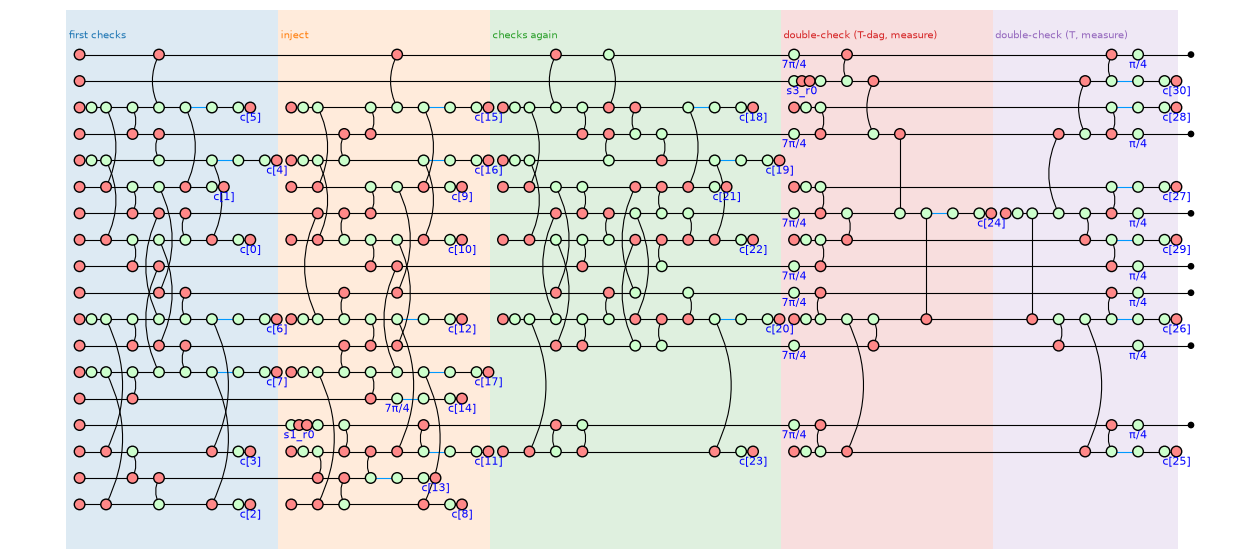

In [2]:
text = open('circuits/cultivation/d3_cultivation.stim').read()
names = ['first checks', 'inject', 'checks again', 'double-check (T-dag, measure)', 'double-check (T, measure)']
real, circ = program_from_stim(text, names=names)
gates = Counter(g.name for st in real.stages for g in st.circuit.gates)
print(real.qubits, "qubits;", sum(gates.values()), "gates:", dict(gates))
print("T gates (T and T-dag):", gates['T'], "; measurements:", gates['Measurement'], "; stages:", real.num_stages)
for s in range(real.num_stages):
    at = real.stage_circuit(s).gates
    print("  stage {}: {:30s} {}".format(s, real.stage(s).name, dict(Counter(g.name for g in at))))
    print("      T gates: {}; results: {}".format(
        ', '.join('{} on qubit {}'.format('T-dag' if g.adjoint else 'T', g.target) for g in at if g.name == 'T') or 'none',
        ', '.join('c[{}]'.format(g.result_bit) for g in at if g.name == 'Measurement')))
fig = draw_program(real, 0, show_time=False, labels=False, figsize=(16, 7))
fig.savefig(FIG + '/d3_circuit.png', bbox_inches='tight')
display(fig)

**What you see.** The circuit has 18 qubits and 231 gates. 15 of them are T gates (T or $T^\dagger$); 31 are measurements.

| stage | T gates | results |
|---|---|---|
| 0 first checks | none | 8 results: `c[0]` to `c[7]` |
| 1 inject | $T^\dagger$ on qubit 13 | 10 results: `c[8]` to `c[17]` |
| 2 checks again | none | 6 results: `c[18]` to `c[23]` |
| 3 double-check, $T^\dagger$ half | $T^\dagger$ on qubits 0, 3, 6, 8, 9, 11, 14 | `c[24]` |
| 4 double-check, T half | T on the same 7 qubits | 6 results: `c[25]` to `c[30]` |

In the picture, each line is a qubit: qubit 0 at the top, qubit 17 at the bottom. (The drawing has no qubit numbers.) Time goes from left to right, and the 5 stages have 5 colours.

* A $T^\dagger$ is drawn as 7π/4, a T as π/4.
* The 7π/4 in stage 1 is on the 14th line: qubit 13.
* Each measurement is labelled with its result `c[j]`.

**What we do.** `code_at(s)` reads which code the qubits are in after stage `s`. It reads this from the diagram; it runs no simulation.

In [3]:
for s in range(real.num_stages):
    print("after stage {} ({}):".format(s, real.stage(s).name))
    for b in real.code_at(s).blocks():
        print("    [[{},{},{}]] on qubits {}{}".format(*b.parameters, list(b.qubits),
                                                     "  (holds a non-Clifford logical state)" if b.non_clifford else ""))
colour_code = real.code_at(real.num_stages - 1)
print()
print("the code at the end:")
print(colour_code)

after stage 0 (first checks):
    [[8,0,None]] on qubits [0, 3, 6, 8, 9, 11, 13, 16]
after stage 1 (inject):
    [[7,1,3]] on qubits [0, 3, 6, 8, 9, 11, 14]  (holds a non-Clifford logical state)
after stage 2 (checks again):
    [[7,1,3]] on qubits [0, 3, 6, 8, 9, 11, 14]  (holds a non-Clifford logical state)
after stage 3 (double-check (T-dag, measure)):
    [[12,3,2]] on qubits [0, 1, 2, 3, 5, 7, 8, 9, 10, 11, 14, 15]  (holds a non-Clifford logical state)
after stage 4 (double-check (T, measure)):


    [[7,1,3]] on qubits [0, 3, 6, 8, 9, 11, 14]  (holds a non-Clifford logical state)

the code at the end:
[[7, 1, 3]] CSS code on qubits 0, 3, 6, 8, 9, 11, 14 (holding a non-Clifford logical state)
    stabilizer (-1)^(c[4])XIIXXXI
    stabilizer (-1)^(c[27])IIXIXXX
    stabilizer (-1)^(c[28] + c[5])IXIXXIX
    stabilizer +ZZZIZII
    stabilizer +ZZIIIZZ
    stabilizer +ZIZZIIZ
    logical X XXIXIII   logical Z ZZIZIII


**What you see.**

| after stage | code |
|---|---|
| 0 | [[8,0]]: no logical qubit yet |
| 1 and 2 | the [[7,1,3]] code on qubits 0, 3, 6, 8, 9, 11, 14 |
| 3 | a [[12,3,2]] code: the double-check is half done |
| 4 | the [[7,1,3]] code again |

From stage 1 on, the code holds a "non-Clifford" logical state: a state that H, S and CNOT gates cannot make. Section 2 shows which state it is at the end: $T^\dagger\vert+\rangle$.

At the end there are 3 X checks and 3 Z checks. The signs of the X checks depend on results, for example $(-1)^{c[4]}$ for `XIIXXXI`. The logical X is `XXIXIII`, the logical Z is `ZZIZIII`.

## 2. Without faults

**What we do.** First, no faults at all. `reduce_gpf` rewrites the whole circuit into a short form, with ZX rules.

We run it twice:

* with the T gadgets kept apart (`gadgets=False`);
* with the T gadgets added up (the default).

A *gadget* is a small piece of the diagram: a red hub with one green leaf. The leaf carries the angle of a T gate. We count spiders and gadgets.

In [4]:
whole = real.quantum_graph()
t0 = time.perf_counter()
kept_apart = reduce_gpf(whole, gadgets=False)
clean = reduce_gpf(whole)
t_reduce = time.perf_counter() - t0
for label, h in (("the circuit", whole), ("reduced, T gadgets kept apart", kept_apart.graph),
                 ("reduced, T gadgets added up", clean.graph)):
    leaves = [v for v in h.vertices() if is_leaf(h, v)]
    print("{:32s} {:4d} spiders, {:2d} T gadgets, angles {}".format(
        label, sum(1 for v in h.vertices() if h.type(v) != 0), len(leaves),
        dict(Counter(str(h.phase(v)) for v in leaves)) if leaves else '-'))
print("both reductions: about {:.1f} s".format(t_reduce))

the circuit                       370 spiders,  0 T gadgets, angles -
reduced, T gadgets kept apart      43 spiders, 15 T gadgets, angles {'c[14] + 7/4': 1, '7/4': 7, '1/4': 7}
reduced, T gadgets added up        13 spiders,  1 T gadgets, angles {'7/4': 1}
both reductions: about 0.2 s


**What you see.**

| diagram | spiders | T gadgets |
|---|---|---|
| the circuit | 370 | 0 (the T gates are still gates) |
| reduced, gadgets kept apart | 43 | 15 |
| reduced, gadgets added up | 13 | 1, angle 7π/4 |

Added up, the 15 T gadgets leave **one** gadget, with angle 7π/4: a $T^\dagger$ on the logical qubit. Kept apart, the angles are 7π/4 (7 times), π/4 (7 times), and once 7π/4 plus π·`c[14]`. Both reductions together take about 0.2 s.

**What we do.** The reduction also gives the *checks*. A check is a sum of results that is 0 in every run without faults.

* `check_detectors` compares them with the DETECTOR lines that the authors wrote in the file. The file's lines are not used to find them.
* We print every check, with a number.
* `draw_checks` draws them: one row per check, a dark square for each result it adds up.

26 declared detector(s): 26 deterministic (value 0), 0 not deterministic, 0 unknown
the program has 26 independent detectors on its results, all sums of declared ones
26 checks on results; the other facts: ['s3_r0', 's1_r0']
  check  1: c[9] = 0
  check  2: c[1] = 0
  check  3: c[0] = 0
  check  4: c[2] = 0
  check  5: c[10] = 0
  check  6: c[8] = 0
  check  7: c[3] = 0
  check  8: c[15] + c[5] = 0
  check  9: c[16] + c[4] = 0
  check 10: c[17] + c[7] = 0
  check 11: c[13] + c[12] + c[6] = 0
  check 12: c[12] + c[6] = 0
  check 13: c[11] = 0
  check 14: c[18] + c[5] = 0
  check 15: c[21] = 0
  check 16: c[23] = 0
  check 17: c[20] + c[12] = 0
  check 18: c[22] = 0
  check 19: c[19] + c[4] = 0
  check 20: c[30] = 0
  check 21: c[29] = 0
  check 22: c[26] = 0
  check 23: c[28] = 0
  check 24: c[25] = 0
  check 25: c[14] + c[24] + c[4] + c[5] + c[6] + c[7] = 0
  check 26: c[14] + c[27] + c[4] + c[5] + c[6] + c[7] = 0


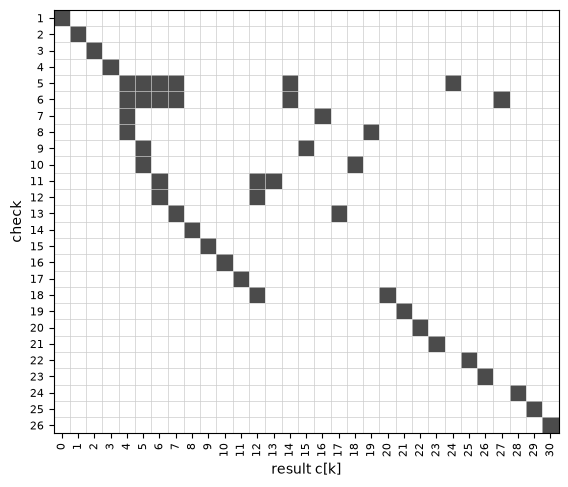

In [5]:
print(check_detectors(real, circ.detectors))
on_results = [d for d in clean.detectors if all(v.name.startswith('c[') for v in d.free_vars())]
print(len(on_results), "checks on results; the other facts:", [str(d) for d in clean.detectors if d not in on_results])
for i, d in enumerate(on_results):
    print("  check {:2d}: {} = 0".format(i + 1, d))
fig = draw_checks(on_results, figsize=(8, 5.5))
fig.savefig(FIG + '/d3_checks.png', bbox_inches='tight')
display(fig)

**What you see.** The reduction finds 26 checks on the results. All 26 DETECTOR lines of the file hold (value 0), and our 26 checks are sums of them: the same checks.

Two more facts, `s3_r0` and `s1_r0`, are values that two resets throw away. Nobody reads them, so they are not checks.

* Most checks read one result. Check 1 is `c[9]` = 0.
* Some read 2 or 3 results. Check 8 is `c[15] + c[5]` = 0.
* Check 23 is `c[28]` = 0, alone.
* Checks 25 and 26 read 6 results: `c[4]`, `c[5]`, `c[6]`, `c[7]`, `c[14]`, and `c[24]` (check 25) or `c[27]` (check 26).

The picture puts its rows in the order of the first result they read. So the rows are not numbered as the list: rows 5 and 6 of the picture are checks 25 and 26.

**What we do.** We put the reduced diagram on the code's own layout.

1. `layout_checks` finds the *faces* of the code: three X checks, drawn as the faces of a triangle.
2. `in_face_variables` writes the diagram in the code's variables: one green spider per face, and one for the logical X.
3. `code_layout(..., regular=True)` gives every spider a place and a height. It also gives the names: S1, S2, S3 for the faces, L for the logical X. The seven qubits sit on a triangle, as in the textbook.

We print the phases of the green spiders twice. First without using the checks (`modulo=False`). Then the default: `in_face_variables` writes each phase *modulo the checks* (a result that a check fixes is replaced). We also print each spider's height, the qubits it is wired to, and its place (x, y).

In [6]:
code = colour_code.data()
faces = code.layout_checks(circ.coords)['X']
print("the faces (X checks) of the code, on qubits", list(code.qubits))
for f in faces:
    print("  ", f, ''.join('X' if q in f else 'I' for q in code.qubits))
plain_lay = code_layout(in_face_variables(clean, code, faces, modulo=False), code.qubits, circ.coords, faces, regular=True)
print("green spiders, checks not used (modulo=False):")
for name, phase in sorted((name, str(plain_lay.graph.phase(v))) for v, name in plain_lay.names.items()):
    print("   {:3s} {}".format(name, phase))
clean_faces = in_face_variables(clean, code, faces)
clean_lay = code_layout(clean_faces, code.qubits, circ.coords, faces, regular=True)
print("green spiders, written modulo the checks (the default), with their height and the qubits they are wired to:")
for name, v in sorted((name, v) for v, name in clean_lay.names.items()):
    print("   {:3s} height {:.0f}, qubits {}: {}".format(name, clean_lay.positions[v][2], sorted(
        code.qubits[clean_lay.qubit_spiders[w]] for w in clean_lay.graph.neighbors(v) if w in clean_lay.qubit_spiders),
        clean_lay.graph.phase(v)))
for logical, state in clean_lay.split:
    print("split off", clean_lay.names[logical], ": a one-legged green spider with phase", clean_lay.graph.phase(state),
          "pi, at height {:.0f}".format(clean_lay.positions[state][2]))
print("how many spiders of each kind, at each height:")
places = Counter((clean_lay.positions[v][2], clean_lay.roles[v]) for v in clean_lay.graph.vertices())
for (height, role), n in sorted(places.items()):
    print("   height {:.0f}: {} {}".format(height, n, role))
print("places (x, y):")
for j, v in sorted((j, v) for v, j in clean_lay.qubit_spiders.items()):
    print("   qubit {:2d}  ({:5.2f}, {:4.2f})".format(code.qubits[j], *clean_lay.positions[v][:2]))
for name, v in sorted((name, v) for v, name in clean_lay.names.items()):
    print("   {:8s}  ({:5.2f}, {:4.2f})".format(name, *clean_lay.positions[v][:2]))
for logical, state in clean_lay.split:
    print("   {:8s}  ({:5.2f}, {:4.2f})".format('state', *clean_lay.positions[state][:2]))

the faces (X checks) of the code, on qubits [0, 3, 6, 8, 9, 11, 14]
   (0, 3, 6, 9) XXXIXII
   (3, 6, 8, 11) IXXXIXI
   (6, 9, 11, 14) IIXIXXX
green spiders, checks not used (modulo=False):
   L   c[6] + c[7] + c[14] + c[28] + c[5] + c[4]
   S1  c[28] + c[5] + c[4] + c[27]
   S2  c[27] + c[28] + c[5]
   S3  c[27]
green spiders, written modulo the checks (the default), with their height and the qubits they are wired to:
   L   height 1, qubits [0, 3, 8]: c[4] + c[5] + c[6] + c[7] + c[14]
   S1  height 2, qubits [0, 3, 6, 9]: c[6] + c[7] + c[14]
   S2  height 2, qubits [3, 6, 8, 11]: c[4] + c[6] + c[7] + c[14]
   S3  height 2, qubits [6, 9, 11, 14]: c[4] + c[5] + c[6] + c[7] + c[14]
split off L : a one-legged green spider with phase 7/4 pi, at height 0
how many spiders of each kind, at each height:
   height 0: 1 state
   height 1: 1 logical
   height 2: 3 face
   height 2: 7 qubit
   height 3: 7 output
places (x, y):
   qubit  0  (-1.00, 0.00)
   qubit  3  (-0.50, 0.87)
   qubit  6  ( 0

**What you see.** The code has 3 faces: qubits (0, 3, 6, 9), (3, 6, 8, 11) and (6, 9, 11, 14). S1, S2 and S3 are wired to exactly these 4 qubits each. **L** is wired to the 3 qubits 0, 3 and 8: the logical X.

| height | spiders |
|---|---|
| 0 | the state $T^\dagger\vert+\rangle$: a one-legged green spider with phase 7π/4, split off L |
| 1 | L |
| 2 | the plane of the code: the 7 qubit spiders and the 3 face spiders S1, S2, S3 |
| 3 | the 7 outputs |

The places (x, y):

* The 7 qubits sit on an even triangle: x from -1 to 1, y from 0 to 1.73. `regular=True` moves them there from the coordinates in the Stim file (`circ.coords`).
* S1, S2, S3 sit inside the triangle, in the middle of their faces.
* L and the state sit outside the triangle, at (-2.41, 1.97). That is beyond the side of qubits 0, 3 and 8: the qubits L is wired to.

The phases of S1, S2, S3 are the signs of their faces. They depend on the results:

| | checks not used | as printed (modulo the checks) |
|---|---|---|
| S3 | `c[27]` | `c[4] + c[5] + c[6] + c[7] + c[14]` |
| S2 | `c[27] + c[28] + c[5]` | `c[4] + c[6] + c[7] + c[14]` |
| S1 | `c[28] + c[5] + c[4] + c[27]` | `c[6] + c[7] + c[14]` |
| L | `c[6] + c[7] + c[14] + c[28] + c[5] + c[4]` | `c[4] + c[5] + c[6] + c[7] + c[14]` |

* S3's face is `IIXIXXX`: an X check of Section 1, with sign $(-1)^{c[27]}$.
* The faces of S2 and S1 are products of X checks of Section 1. So they read sums of those signs.
* By default, each phase is written modulo the checks of the list above. Check 23 says `c[28]` = 0, so `c[28]` drops out. Check 26 says that `c[27]` equals `c[4] + c[5] + c[6] + c[7] + c[14]`. Put in, this gives the column "as printed".
* On L, `c[4] + c[5] + c[6] + c[7] + c[14]` says when a logical Z is on top of $T^\dagger\vert+\rangle$.

**What we do.** Two pictures of **one run**, in the same style as `Cultivation.ipynb`: the run where every result is 0. We set the results to 0 for the pictures only.

First we print every spider that has a phase, with its variables. Then:

* `draw_graph_3d`: the whole diagram, on its planes, seen from the side (`view=(18, -55)`);
* `draw_slice`: the plane at height 2 alone, flat.

every spider with a phase, with its variables (times pi):
   L      c[4] + c[5] + c[6] + c[7] + c[14]
   S1     c[6] + c[7] + c[14]
   S2     c[4] + c[6] + c[7] + c[14]
   S3     c[4] + c[5] + c[6] + c[7] + c[14]
   state  7/4
the other 7 spiders have phase 0
the pictures show one run: these 5 variables set to 0: ['c[14]', 'c[4]', 'c[5]', 'c[6]', 'c[7]']
phases left in that run: ['7/4']


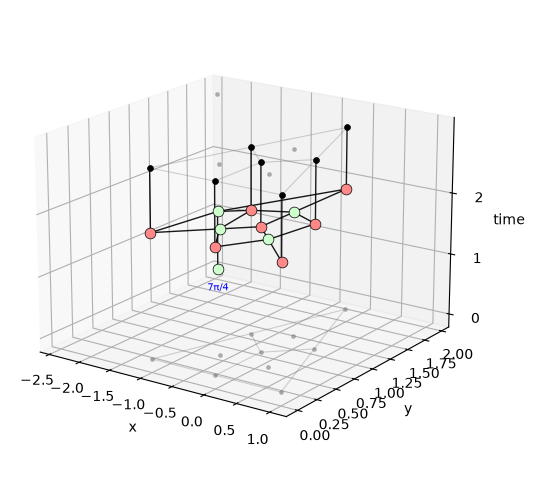

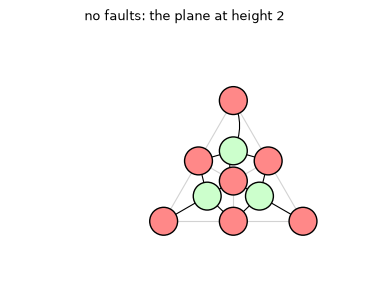

In [7]:
print("every spider with a phase, with its variables (times pi):")
for v in clean_lay.graph.vertices():
    if clean_lay.graph.phase(v) != 0:
        print("   {:6s} {}".format(clean_lay.names.get(v, clean_lay.roles[v]), clean_lay.graph.phase(v)))
print("the other {} spiders have phase 0".format(sum(1 for v in clean_lay.graph.vertices() if clean_lay.graph.phase(v) == 0
                                                     and clean_lay.graph.type(v) != VertexType.BOUNDARY)))
run0 = clean_lay.graph.substitute_variables({v: 0 for v in boolean_variables(clean_lay.graph)})
print("the pictures show one run: these {} variables set to 0: {}".format(
    len(boolean_variables(clean_lay.graph)), sorted(boolean_variables(clean_lay.graph))))
print("phases left in that run:", [str(run0.phase(v)) for v in run0.vertices() if run0.phase(v) != 0])
fig = draw_graph_3d(run0, clean_lay.topology, positions=clean_lay.positions, view=(18, -55))
fig.savefig(FIG + '/d3_clean_3d.png', bbox_inches='tight')
display(fig)
fig = draw_slice(run0, clean_lay.topology, z=2, positions=clean_lay.positions, title='no faults: the plane at height 2',
                 figsize=(4.5, 4))
fig.savefig(FIG + '/d3_clean_plane.png', bbox_inches='tight')
display(fig)

**What you see.** The list gives every spider with a phase, with its variables: L, S1, S2 and S3 read results; the state reads 7π/4. The other 7 spiders (the qubits) have phase 0.

Only 5 results are in this diagram: `c[4]`, `c[5]`, `c[6]`, `c[7]`, `c[14]`. We set them to 0, for the pictures only. Every check is a sum of results, so this run passes all checks. The only phase left is 7π/4.

* **3D.** The plane of the code at height 2: 7 red qubits and 3 green face spiders. The 7 outputs (black dots) stand above it. The faint grey lines at the bottom and the top are the sides of the faces.
* **L in the 3D picture.** Seen from this side, L is far behind the triangle. So it is drawn inside the triangle, just above S1: the two green spiders almost touch. The lowest green spider is the state, with 7π/4 under it.
* The upright axis is named "time", but here it is only the height in the layout, as in `Cultivation.ipynb`.
* **Flat.** The plane at height 2 alone: the textbook picture of the Steane code. 7 red qubits on a triangle, and a green spider in the middle of each face. L is not in this plane.
* The pictures have no names. The names L, S1, S2, S3 are only in the printed lists.

**What we do.** Is the diagram on the code's layout still the circuit? The pictures show one run. Here we take the diagram with all its variables (`clean_lay.graph`), in every run that the checks allow. We compute it and the circuit as matrices, and compare them (`equal_for_all_assignments`).

"The same map" means: equal up to a number that is not zero, in each run.

In [8]:
variables = sorted(set(boolean_variables(whole)) | {str(v) for c in clean.constraints for v in c.free_vars()})
runs = consistent_assignments(clean.constraints, variables)
t0 = time.perf_counter()
print(len(variables), "variables;", len(runs), "runs allowed by the checks")
print("the diagram on the code's layout, with its variables, is the same map as the circuit in every allowed run:",
      equal_for_all_assignments(whole, clean_lay.graph, variables, clean.constraints),
      "(about {:.1f} s)".format(time.perf_counter() - t0))

33 variables; 32 runs allowed by the checks


the diagram on the code's layout, with its variables, is the same map as the circuit in every allowed run: True (about 2.8 s)


**What you see.** There are 33 variables, and the checks allow 32 runs. In all 32 runs the diagram on the code's layout, with its variables, is the same map as the circuit, up to a number (about 2.8 s).

## 3. Every fault as a switch

**What we do.** Now the faults. A *fault* here is a Pauli error right after one gate, on its qubits: X, Y or Z after a one-qubit gate; any two-qubit Pauli except II (15 of them) after a CNOT.

* After every gate (not after a measurement), on each qubit of the gate, there is a *place*.
* Place `k` gets two *switches*, `x_k` and `z_k`. Each is 0 or 1. The error at place `k` is $X^{x_k} Z^{z_k}$. So every Pauli fault after every gate is one value of the switches.
* `error_formulas` pushes every switch to the end of the circuit, with the rules that move a Pauli past a gate.
* An X that reaches a T gate turns it into $T^\dagger$ (and a $T^\dagger$ into T). So each T gate gets a *T switch* `f_i`. It is not a new error. It is the sum of the switches that reach that gate as an X.

We print the sizes, and the T switches.

In [9]:
t0 = time.perf_counter()
ef = error_formulas(real)
print("error_formulas: about {:.2f} s".format(time.perf_counter() - t0))
print(len(ef.places), "places;", 2 * len(ef.places), "switches (x_k and z_k);", len(ef.t_flips), "T switches (f_i);",
      len(ef.flips), "results;", len(ef.frame), "output qubits", sorted(ef.frame))
print()
print("the T switches:")
for t in ef.t_flips:
    print("  {:3s} the {:5s} on qubit {:2d} (stage {}); {} switches reach it as an X".format(
        t.name, 'T-dag' if t.adjoint else 'T', t.qubit, t.stage, len(t.switches)))

error_formulas: about 0.51 s
304 places; 608 switches (x_k and z_k); 15 T switches (f_i); 31 results; 7 output qubits [0, 3, 6, 8, 9, 11, 14]

the T switches:
  f0  the T-dag on qubit 13 (stage 1); 10 switches reach it as an X
  f1  the T-dag on qubit  0 (stage 3); 16 switches reach it as an X
  f2  the T-dag on qubit  3 (stage 3); 28 switches reach it as an X
  f3  the T-dag on qubit  6 (stage 3); 51 switches reach it as an X
  f4  the T-dag on qubit  8 (stage 3); 30 switches reach it as an X
  f5  the T-dag on qubit  9 (stage 3); 36 switches reach it as an X
  f6  the T-dag on qubit 11 (stage 3); 45 switches reach it as an X
  f7  the T-dag on qubit 14 (stage 3); 34 switches reach it as an X
  f8  the T     on qubit  0 (stage 4); 72 switches reach it as an X
  f9  the T     on qubit  3 (stage 4); 71 switches reach it as an X
  f10 the T     on qubit  6 (stage 4); 9 switches reach it as an X
  f11 the T     on qubit  8 (stage 4); 69 switches reach it as an X
  f12 the T     on qubit  

**What you see.** One call, about 0.51 s:

| what | how many |
|---|---|
| places | 304 |
| switches (`x_k` and `z_k`) | 608 |
| T switches `f_i` (sums of switches, not new ones) | 15 |
| results | 31 |
| output qubits | 7 (0, 3, 6, 8, 9, 11, 14) |

* `f0` is the $T^\dagger$ of the injection (qubit 13, stage 1).
* `f1` to `f7` are the 7 $T^\dagger$ gates of stage 3; `f8` to `f14` the 7 T gates of stage 4.
* Between 9 and 92 switches reach a T gate as an X.

**What we do.** A legend: after which gate is each place `k`? `ef.places` lists them. Each entry reads `k: gate(qubit)`.

In [10]:
print("place k: gate (qubit)")
for s in range(real.num_stages):
    at = [pl for pl in ef.places if pl.stage == s]
    print("stage {} ({}): places {} to {}".format(s, real.stage(s).name, at[0].index, at[-1].index))
    print(textwrap.fill('  '.join('{}: {}({})'.format(pl.index, pl.name, pl.qubit) for pl in at), width=118,
                        initial_indent='    ', subsequent_indent='    '))

place k: gate (qubit)
stage 0 (first checks): places 0 to 73
    0: Reset(1)  1: Reset(14)  2: Reset(4)  3: HAD(4)  4: Reset(2)  5: HAD(2)  6: Reset(10)  7: HAD(10)  8: Reset(12)
    9: HAD(12)  10: Reset(0)  11: Reset(9)  12: Reset(16)  13: Reset(11)  14: Reset(6)  15: Reset(3)  16: Reset(13)
    17: Reset(8)  18: Reset(7)  19: Reset(5)  20: Reset(17)  21: Reset(15)  22: CNOT(2)  23: CNOT(5)  24: CNOT(4)  25:
    CNOT(7)  26: CNOT(10)  27: CNOT(15)  28: CNOT(12)  29: CNOT(17)  30: CNOT(2)  31: CNOT(3)  32: CNOT(5)  33:
    CNOT(6)  34: CNOT(7)  35: CNOT(8)  36: CNOT(10)  37: CNOT(11)  38: CNOT(12)  39: CNOT(13)  40: CNOT(15)  41:
    CNOT(16)  42: CNOT(2)  43: CNOT(0)  44: CNOT(5)  45: CNOT(9)  46: CNOT(7)  47: CNOT(11)  48: CNOT(10)  49: CNOT(6)
    50: CNOT(12)  51: CNOT(8)  52: CNOT(4)  53: CNOT(3)  54: CNOT(7)  55: CNOT(6)  56: CNOT(10)  57: CNOT(9)  58:
    CNOT(12)  59: CNOT(11)  60: CNOT(17)  61: CNOT(16)  62: CNOT(2)  63: CNOT(5)  64: CNOT(4)  65: CNOT(7)  66:
    CNOT(10)  67

**What you see.**

| stage | places |
|---|---|
| 0 first checks | 0 to 73 |
| 1 inject | 74 to 148 |
| 2 checks again | 149 to 220 |
| 3 double-check, $T^\dagger$ half | 221 to 264 |
| 4 double-check, T half | 265 to 303 |

A CNOT has two places, one on each of its qubits. A Reset, HAD or T gate has one. The example pair of Section 5 uses place 252 (`CNOT(3)`, stage 3) and place 286 (`CNOT(8)`, stage 4).

**What we do.** `switched_program` is the circuit with its switches in it. We draw one stage only: stage 3, the first half of the double-check.

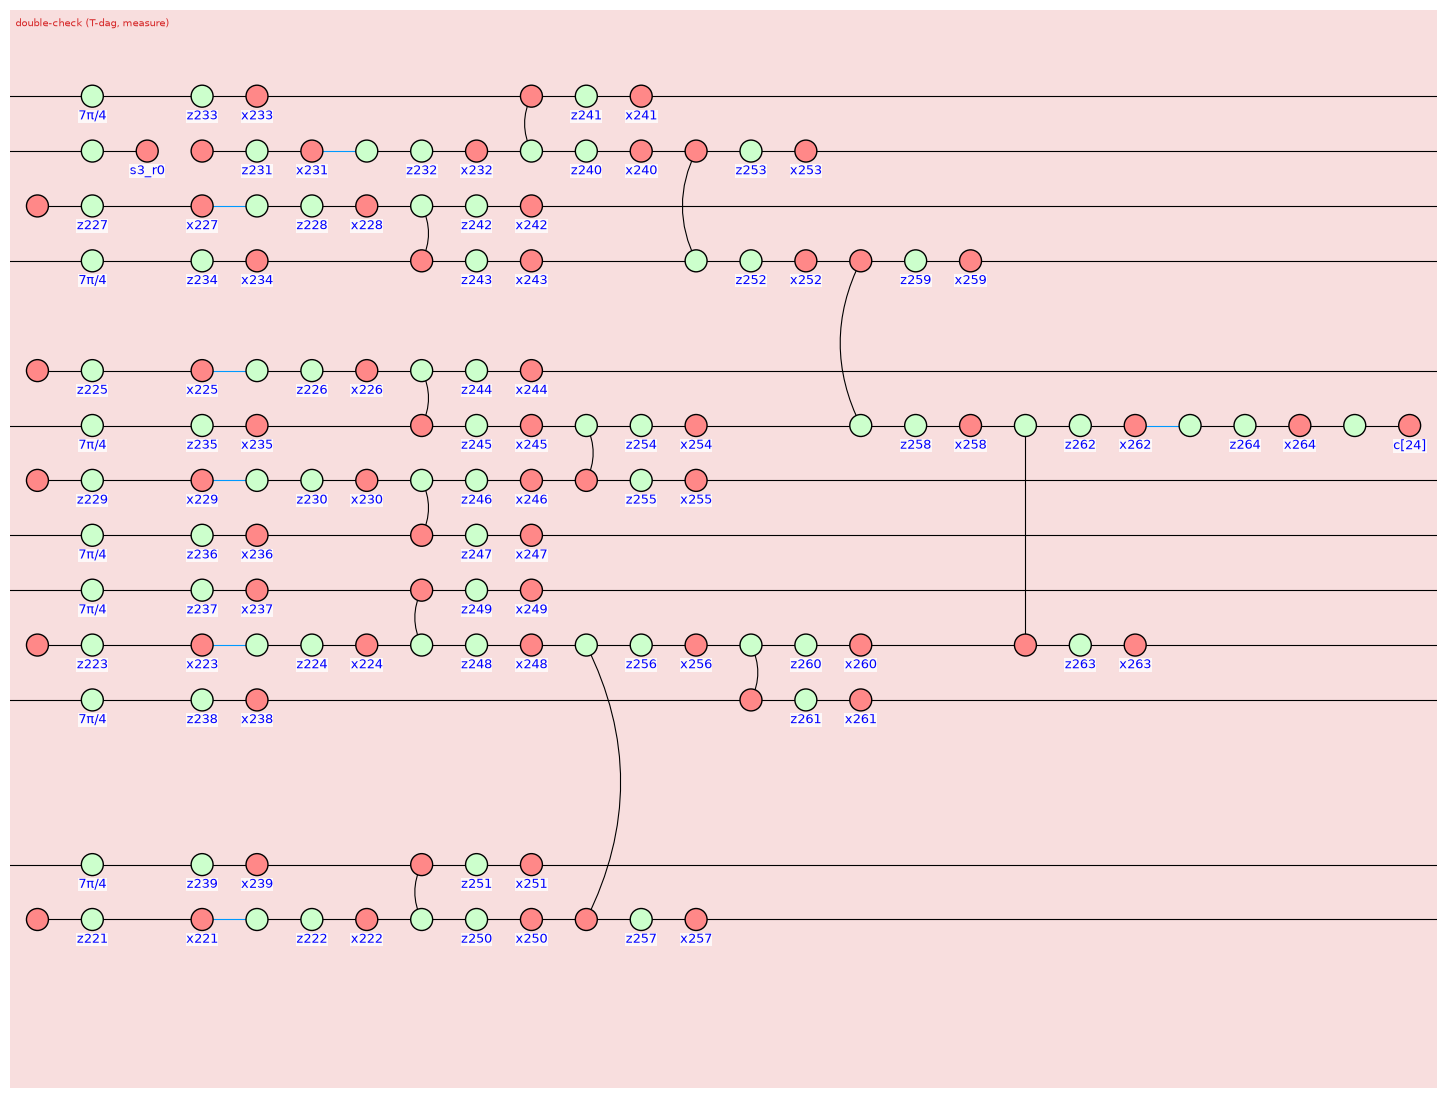

In [11]:
fig = draw_program(ef.switched_program(), 0, time_axis=False, show_time=False, even_rows=True, labels_above=True,
                   figsize=(20, 14), blocks=[3], label_size=9)
fig.savefig(FIG + '/d3_switched_stage3.png', bbox_inches='tight')
display(fig)

**What you see.** Stage 3, with its switches.

* After every gate, on each qubit of the gate, there is a green spider `z_k` and a red spider `x_k`.
* The top line is qubit 0: its `x233` belongs to place 233, `T(0)` in the legend.
* `x252` is on the 4th line: qubit 3 (place 252 is `CNOT(3)`).
* The 7π/4 spiders on the left are the $T^\dagger$ gates.

For every value of the switches, this one diagram is the circuit with those errors.

## 4. The reduced diagram, with every variable kept

**What we do.** `error_formulas` pushed every switch to the end (Section 3). What is left is the circuit with these variables in it:

* the 15 T switches `f_i`;
* the X and Z part of the Pauli left on each output qubit, `ox q` and `oz q`;
* the results `c[j]`.

It reduced this circuit **once**: `ef.reduced`. The 608 switches are not in it. They are only in the formulas (Section 5).

We keep every variable: none is set to a value.

* We write the diagram in the faces' variables (`in_face_variables` with `simplify=False, modulo=False`: only the variables change).
* `code_layout` gives the green spiders their names: L, S1, S2, S3, h1, h2. We use it here for the names and kinds of the spiders.
* We count what is in it.
* We print every phase that has a variable, with a name for its spider (`lay.phase_list()`). In this list the gadget hubs get the names g1, g2, ...
* We draw it flat, as a GPF (`layout_gpf` and `draw_graph`), in the same style as the paper. The long phases would cover the picture. So the picture writes only the gadget angles (`phases='constant'`), and names: the green spiders on the left (`names`), the hubs $g_i$ and the outputs $q_k$ on the right (`names_right`). The phases are in the printed list.

spiders: the circuit 370; reduced with f, ox, oz kept 43; reduced without faults 13
T gadgets: 15; angles {'7/4': 8, '5/4': 7}
variables in the drawn diagram: 15 f, 7 ox, 7 oz, 8 results, 0 other []
every phase with a variable, by name (lay.phase_list()):
  L        c[4] + c[5] + c[6] + c[7] + c[14] + c[28] + oz0 + oz3 + oz8 + 1
  S1       c[4] + c[5] + c[27] + c[28] + oz0 + oz3 + oz6 + oz9
  S2       c[5] + c[27] + c[28] + oz3 + oz6 + oz8 + oz11
  S3       c[27] + oz6 + oz9 + oz11 + oz14
  h1       c[4] + c[5] + c[6] + c[7] + c[14] + c[24]
  h2       c[4] + c[5] + c[6] + c[7] + c[14] + c[27]
  qubit 0  ox0 + ox8 + ox9 + ox11
  qubit 3  ox3 + ox8 + ox9 + ox14
  qubit 6  ox6 + ox9 + ox11 + ox14
  g1       f0 + ox8 + ox11 + ox14
  g2       f1 + ox8 + ox9 + ox11
  g3       f2 + ox8 + ox9 + ox14
  g4       f3 + ox9 + ox11 + ox14
  g5       f4 + ox8
  g6       f5 + ox9
  g7       f6 + ox11
  g8       f7 + ox14
  g9       f8 + ox8 + ox9 + ox11
  g10      f9 + ox8 + ox9 + ox14
  g11      f10 

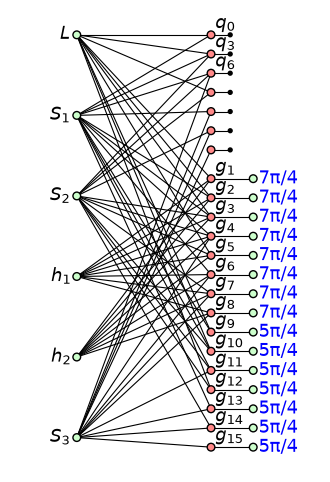

In [12]:
reduced = ef.reduced.to_graph()
every = in_face_variables(ef.reduced, code, faces, simplify=False, modulo=False)    # only the variables change
lay = code_layout(every, code.qubits, circ.coords, faces, regular=True)    # the names; it works on its own copy (lay.graph)
G = lay.graph
kinds = Counter('f' if v[0] == 'f' else v[:2] if v[:2] in ('ox', 'oz') else 'c' if v.startswith('c[') else 'other'
                for v in boolean_variables(G))
print("spiders: the circuit {}; reduced with f, ox, oz kept {}; reduced without faults {}".format(
    sum(1 for v in whole.vertices() if whole.type(v) != 0), sum(1 for v in reduced.vertices() if reduced.type(v) != 0),
    sum(1 for v in clean.graph.vertices() if clean.graph.type(v) != 0)))
print("T gadgets: {}; angles {}".format(len(phase_polynomial(G)[1]),
                                        dict(Counter(str(G.phase(ls[0])) for _h, ls in phase_polynomial(G)[1]))))
print("variables in the drawn diagram: {} f, {} ox, {} oz, {} results, {} other {}".format(
    kinds['f'], kinds['ox'], kinds['oz'], kinds['c'], kinds['other'],
    sorted(v for v in boolean_variables(G) if not (v[0] == 'f' or v[:2] in ('ox', 'oz') or v.startswith('c[')))))
print("every phase with a variable, by name (lay.phase_list()):")
for name, phase in lay.phase_list():
    print("  {:8s} {}".format(name, phase))
layout_gpf(every, leaf_gap=2.2)                        # the GPF drawing; only the places of the spiders change
green_names = {v: '${}_{{{}}}$'.format(n[0], n[1:]) if len(n) > 1 else '$' + n + '$' for v, n in lay.names.items()}
hub_names = {hub: '$g_{{{}}}$'.format(int(next(x.name for x in every.phase(hub).free_vars() if x.name[0] == 'f')[1:]) + 1)
             for hub, _ls in phase_polynomial(every)[1]}
out_names = {next(iter(every.neighbors(b))): '$q_{{{}}}$'.format(q) for q, b in zip(code.qubits, every.outputs())
             if every.phase(next(iter(every.neighbors(b)))) != 0}
print("names in the picture: green, from the top", [green_names[v] for v in sorted(green_names, key=every.qubit)],
      "; hubs, from the top", [hub_names[h] for h in sorted(hub_names, key=every.qubit)],
      "; outputs with a phase", [out_names[v] for v in sorted(out_names, key=every.qubit)])
fig = draw_graph(every, time_axis=False, show_time=False, label_size=13, label_side='right', figsize=(4, 6),
                 names=green_names, names_right=hub_names | out_names, phases='constant')
fig.savefig(FIG + '/d3_every_variable_2d.png', bbox_inches='tight')
display(fig)

**What you see.**

| diagram | spiders |
|---|---|
| the circuit | 370 |
| reduced, with `f`, `ox`, `oz` kept | 43 |
| reduced, no faults (Section 2) | 13 |

With faults, the 15 T gadgets stay **15 gadgets**, one per T gate: 8 with angle 7π/4 (the $T^\dagger$ gates) and 7 with angle 5π/4 (the T gates). The drawn diagram has all 15 `f`, 7 `ox`, 7 `oz` and 8 results in it. Nothing was set to a value. (The other results are only in the checks.)

**The list** gives every phase that has a variable, by name:

* L, S1, S2, S3, h1, h2: the green spiders.
* qubit 0, qubit 3, qubit 6: the output spiders that have a phase. In the picture they are $q_0$, $q_3$, $q_6$.
* g1 to g15: the gadget hubs, one per T gate. These names count from 1, the T switches from 0: `g1` reads `f0`, and `g15` reads `f14`.
* The leaves are not in the list. Their angles are numbers, and the picture shows them.

What the green spiders read:

| green spider | reads |
|---|---|
| L | `oz0`, `oz3`, `oz8` (its 3 qubits), results, and a constant 1 |
| S1, S2, S3 | the `oz` of the 4 qubits of its face, and results |
| h1, h2 | results only |

**The picture** shows the names printed just above it:

* On the left, the 6 green spiders, with their names. From the top: L, S1, S2, h1, h2, S3.
* In the middle, the red spiders. The top 7 are the outputs. Only the first three have a phase: $q_0$, $q_3$, $q_6$. The 15 below them are the gadget hubs, $g_1$ to $g_{15}$ from the top.
* On the right, the 15 leaves with their angles: 7π/4 for $g_1$ to $g_8$, 5π/4 for $g_9$ to $g_{15}$.
* The phases with variables are left out of the picture: they would cover it. They are in the list. Nothing is set to 0.

Why 5π/4 and not π/4? 5π/4 = π/4 + π. We do not move the extra π away: the step that does it (`normalize_gadget_angles`) drops a sign that depends on the variables. The checks below are on this diagram as drawn.

**What we do.** For each green spider: its kind (`lay.roles`), and how many output qubits and gadget hubs it is wired to.

In [13]:
print("the green spiders: their kind, and how many output qubits and gadget hubs each is wired to:")
for name, v in sorted((name, v) for v, name in lay.names.items()):
    print("  {:3s} {:8s} {} qubits, {} hubs".format(name, lay.roles[v], sum(1 for w in G.neighbors(v) if w in lay.qubit_spiders),
                                                sum(1 for w in G.neighbors(v) if lay.roles.get(w) == 'hub')))

the green spiders: their kind, and how many output qubits and gadget hubs each is wired to:
  L   logical  3 qubits, 7 hubs
  S1  face     4 qubits, 8 hubs
  S2  face     4 qubits, 8 hubs
  S3  face     4 qubits, 8 hubs
  h1  hidden   0 qubits, 8 hubs
  h2  hidden   0 qubits, 8 hubs


**What you see.** How the green spiders are wired:

| green spider | kind | output qubits | gadget hubs |
|---|---|---|---|
| L | logical | 3 | 7 |
| S1, S2, S3 | face | 4 each | 8 each |
| h1, h2 | hidden | 0 | 8 each |

h1 and h2 are the two *hidden* green spiders: they are wired to no output qubit, only to gadget hubs.

**What we do.** We print what the other parts of the diagram read:

* each output spider that has a phase;
* each gadget hub, with the T gate it comes from and the angle of its leaf.

For an output spider we also ask the code (`code.contains`): are Z operators on its qubits a check of the code?

In [14]:
print("output spiders with a phase:")
for j, v in sorted((j, v) for v, j in lay.qubit_spiders.items()):
    if G.phase(v) != 0:
        qs = sorted(int(x.name[2:]) for x in G.phase(v).free_vars())
        z = ''.join('Z' if q in qs else 'I' for q in code.qubits)
        print("  qubit {:2d}: {:28s} -> X errors on qubits {}; Z on them ({}) is a check of the code: {}".format(
            code.qubits[j], str(G.phase(v)), qs, z, code.contains(z)))
print("gadget hubs (which T gate | hub phase | leaf angle):")
ox_in_hubs = set()
for v, role in lay.roles.items():
    if role == 'hub':
        f = next(x.name for x in G.phase(v).free_vars() if x.name[0] == 'f')
        t = next(t for t in ef.t_flips if t.name == f)
        leaf = next(w for w in G.neighbors(v) if lay.roles.get(w) == 'leaf')
        ox_in_hubs |= {x.name for x in G.phase(v).free_vars() if x.name[:2] == 'ox'}
        print("  {:5s} on qubit {:2d} (stage {}) | {:26s} | {}".format('T-dag' if t.adjoint else 'T', t.qubit, t.stage,
                                                                  str(G.phase(v)), G.phase(leaf)))
print("the ox in the hubs:", [x for x in ('ox{}'.format(q) for q in code.qubits) if x in ox_in_hubs])

output spiders with a phase:
  qubit  0: ox9 + ox0 + ox11 + ox8       -> X errors on qubits [0, 8, 9, 11]; Z on them (ZIIZZZI) is a check of the code: True
  qubit  3: ox3 + ox8 + ox14 + ox9       -> X errors on qubits [3, 8, 9, 14]; Z on them (IZIZZIZ) is a check of the code: True
  qubit  6: ox14 + ox9 + ox11 + ox6      -> X errors on qubits [6, 9, 11, 14]; Z on them (IIZIZZZ) is a check of the code: True
gadget hubs (which T gate | hub phase | leaf angle):
  T-dag on qubit 13 (stage 1) | f0 + ox8 + ox14 + ox11     | 7/4
  T-dag on qubit  0 (stage 3) | f1 + ox9 + ox11 + ox8      | 7/4
  T-dag on qubit  3 (stage 3) | f2 + ox8 + ox14 + ox9      | 7/4
  T-dag on qubit  6 (stage 3) | f3 + ox14 + ox9 + ox11     | 7/4
  T-dag on qubit  8 (stage 3) | f4 + ox8                   | 7/4
  T-dag on qubit  9 (stage 3) | f5 + ox9                   | 7/4
  T-dag on qubit 11 (stage 3) | f6 + ox11                  | 7/4
  T-dag on qubit 14 (stage 3) | f7 + ox14                  | 7/4
  T     on qubit

**What you see.**

| part | reads |
|---|---|
| hub of a T gate | its switch `f_i`, plus some of `ox8`, `ox9`, `ox11`, `ox14` |
| output spider of qubit 0 | `ox0 + ox8 + ox9 + ox11` |
| output spider of qubit 3 | `ox3 + ox8 + ox9 + ox14` |
| output spider of qubit 6 | `ox6 + ox9 + ox11 + ox14` |

(The output prints the terms of a sum in another order.)

* A hub reads `f_i`. When it is 1, that T gate turns around: T becomes $T^\dagger$, and $T^\dagger$ becomes T. An `ox` in a hub does the same to that gadget.
* An output spider reads the X errors on 4 qubits. Z on these 4 qubits is a check of the code (`code.contains`: True for all three). So the sum is 1 exactly when the X errors make this Z check fire.
* These Z checks are the X checks of Section 1 with Z in place of X: `XIIXXXI` gives `ZIIZZZI` (qubit 0), `IXIXXIX` gives `IZIZZIZ` (qubit 3), `IIXIXXX` gives `IIZIZZZ` (qubit 6).
* The T gates read 5π/4, the $T^\dagger$ gates 7π/4, as in the picture above.

**What we do.** Is the drawn diagram the same map as `ef.reduced`? There are too many variables to try every value. So we try random values of **all** variables, with fixed seeds 0, 1, 2, ...

* `sample_consistent_assignment` picks values that the checks of the circuit allow.
* With faults, some of these runs cannot happen. Then the map is zero: every entry of its matrix is 0. There the drawn diagram must be zero too.
* We go on until 30 values give a map that is not zero. `same_map` compares the two maps on these (up to a number that is not zero).
* Two controls: we change one variable on one side only, `f8` (a T switch) or `oz0` (a Z on output qubit 0). Then the maps should differ.

In [15]:
variables = sorted(set(boolean_variables(reduced, G)) | {str(v) for v in reduced.scalar.phase.free_vars()}
                   | {str(v) for v in G.scalar.phase.free_vars()}
                   | {str(v) for c in ef.reduced.constraints for v in c.free_vars()})
print(len(variables), "variables:", Counter('f' if v[0] == 'f' else v[:2] if v[:2] in ('ox', 'oz') else
                                            'c' if v.startswith('c[') else 'other' for v in variables))
t0 = time.perf_counter()
tried = zero = zero_too = compared = same = 0
differs = Counter()
while compared < 30:
    values = sample_consistent_assignment(ef.reduced.constraints, variables, random.Random(tried))
    tried += 1
    a, b = reduced.substitute_variables(values), G.substitute_variables(values)
    if abs(a.to_tensor()).max() < 1e-9:                    # the zero map: a run that cannot happen with these values
        zero += 1
        zero_too += same_map(a, b)                         # the drawn diagram must be the zero map too
        continue
    compared += 1
    same += same_map(a, b)
    for name in ('f8', 'oz0'):                             # controls: one variable changed on one side only
        differs[name] += not same_map(a, G.substitute_variables(dict(values, **{name: 1 - values[name]})))
print("{} random values of all {} variables (seeds 0 to {}):".format(tried, len(variables), tried - 1))
print("  {} give the zero map (a run that cannot happen with these values); the drawn diagram is zero too in {}".format(
    zero, zero_too))
print("  {} give a map that is not zero; the drawn diagram = error_formulas' reduced diagram in {} of them".format(
    compared, same))
for name in ('f8', 'oz0'):
    print("  control, {} changed on one side only: differs in {} of {}".format(name, differs[name], compared))
print("(about {:.1f} s)".format(time.perf_counter() - t0))

62 variables: Counter({'c': 31, 'f': 15, 'ox': 7, 'oz': 7, 'other': 2})


65 random values of all 62 variables (seeds 0 to 64):
  35 give the zero map (a run that cannot happen with these values); the drawn diagram is zero too in 35
  30 give a map that is not zero; the drawn diagram = error_formulas' reduced diagram in 30 of them
  control, f8 changed on one side only: differs in 30 of 30
  control, oz0 changed on one side only: differs in 30 of 30
(about 12.8 s)


**What you see.** 62 variables in all: 31 results, 15 `f`, 7 `ox`, 7 `oz`, and 2 others. We tried 65 random values.

* 35 of them give the zero map: with these faults, that run cannot happen. The drawn diagram is zero there too (35 of 35).
* 30 give a map that is not zero. In 30 of them the drawn diagram is the same map as `ef.reduced`, up to a number.
* Control `f8`: the maps differ in 30 of 30. Control `oz0`: in 30 of 30.

So the check does see a change. It took about 12.8 s.

## 5. All the equations

**What we do.** Every formula, in full (`ef.formula`). A formula is a sum of switches. It is 1 when an odd number of its switches are on.

In [16]:
print("The {} T switches (f_i is 1 when the sum is odd):".format(len(ef.t_flips)))
for t in ef.t_flips:
    print("  {} = {}".format(t.name, ef.formula(t.name)))
print()
print("The {} results (c[j] flips when the sum is odd):".format(len(ef.flips)))
for c in ('c[{}]'.format(j) for j in range(len(ef.flips))):
    print("  {} = {}".format(c, ef.formula(c)))
print()
print("The Pauli left on the {} output qubits (X part ox, Z part oz):".format(len(ef.frame)))
for q in sorted(ef.frame):
    print("  ox{} ({} switches) = {}".format(q, len(ef.frame[q][0]), ef.formula('ox{}'.format(q))))
    print("  oz{} ({} switches) = {}".format(q, len(ef.frame[q][1]), ef.formula('oz{}'.format(q))))

The 15 T switches (f_i is 1 when the sum is odd):
  f0 = z8 + x9 + x16 + x28 + x39 + z80 + x81 + x95 + x105 + x120
  f1 = z4 + x5 + x10 + x22 + x30 + x43 + z76 + x77 + x89 + x111 + x124 + z149 + x150 + x158 + x165 + x188
  f2 = z2 + x3 + z4 + x5 + x15 + x22 + x24 + x31 + x53 + z74 + x75 + z76 + x77 + x89 + x91 + x100 + x112 + z149 + x150 + z151 + x152 + x158 + x160 + x164 + x173 + x181 + x196 + x204
  f3 = z2 + x3 + z4 + x5 + z6 + x7 + x14 + x18 + x19 + x23 + x25 + x26 + x33 + x34 + x36 + x46 + x49 + x55 + z74 + x75 + z76 + x77 + z78 + x79 + x86 + x87 + x90 + x92 + x94 + x102 + x114 + z149 + x150 + z151 + x152 + z153 + x154 + x155 + x156 + x159 + x161 + x162 + x166 + x168 + x171 + x175 + x176 + x183 + x190 + x198 + x206
  f4 = z2 + x3 + z8 + x9 + x17 + x18 + x25 + x28 + x35 + x38 + x51 + z74 + x75 + z80 + x81 + x86 + x92 + x95 + x101 + x105 + x116 + x119 + x132 + z151 + x152 + x156 + x161 + x168 + x177 + x200
  f5 = z4 + x5 + z6 + x7 + x11 + x19 + x23 + x26 + x32 + x36 + x45 + x48 + x5

**What you see.** Every formula, in full.

* **T switches.** `f10` is the shortest (9 switches), `f14` the longest (92).
* **Results.** Some read only `x` switches, for example `c[0] = x18 + x24 + ...`: an X error flips a measured result. Others also read `z` switches, for example `c[4] = x2 + z3 + ...`: a Hadamard turns a Z error into an X before the measurement.
* **Outputs.** `ox q` and `oz q` are the X and Z part of the Pauli left on output qubit `q`. `oz14` is short (9 switches); `ox14` is long.

**What we do.** Every check, as a sum of switches (`ef.detector_switches`). A check fires when its sum is odd. We also test that these are the checks of Section 2, in the same order, so that the numbers match.

In [17]:
checks = ef.detector_switches()
check_switches = [(d, s) for d, s in checks if all(v.name.startswith('c[') for v in d.free_vars())]
print(len(checks), "facts of the circuit without faults;", len(check_switches), "of them are checks on results.")
print("the same checks, in the same order, as in Section 2:", [str(d) for d, s in check_switches] == [str(d) for d in on_results])
for i, (d, s) in enumerate(check_switches):
    print("  check {:2d}: {} fires when {} is odd".format(i + 1, d, ef.formula(s)))
print("how many switches in checks 1 to 7:", [len(s) for d, s in check_switches[:7]])
print("the other facts (values that a reset throws away, not checks):",
      [str(d) for d, s in checks if (d, s) not in check_switches])

28 facts of the circuit without faults; 26 of them are checks on results.
the same checks, in the same order, as in Section 2: True
  check  1: c[9] fires when x87 + x89 + x90 + x111 + x113 + x123 + x125 + x134 is odd
  check  2: c[1] fires when x19 + x22 + x23 + x30 + x32 + x42 + x44 + x63 is odd
  check  3: c[0] fires when x18 + x24 + x25 + x34 + x46 + x52 + x54 + x65 is odd
  check  4: c[2] fires when x20 + x28 + x29 + x38 + x50 + x58 + x60 + x69 is odd
  check  5: c[10] fires when x86 + x91 + x92 + x99 + x101 + x115 + x127 + x136 is odd
  check  6: c[8] fires when x88 + x95 + x96 + x105 + x109 + x119 + x131 + x138 is odd
  check  7: c[3] fires when x21 + x26 + x27 + x36 + x40 + x48 + x56 + x67 is odd
  check  8: c[15] + c[5] fires when x4 + z5 + z22 + z23 + z30 + z31 + z32 + z33 + z42 + z43 + z44 + z45 + z49 + z53 + z55 + z57 + z62 + x71 + x76 + z77 + z89 + z90 + z94 + z100 + z102 + z104 + z111 + z113 + z123 + z125 + z133 + x146 is odd
  check  9: c[16] + c[4] fires when x2 + z3 + 

**What you see.** 28 facts; 26 of them are checks on results. They are the 26 checks of Section 2, in the same order (True).

* A check is a sum of results, so its switches are the sum of their formulas. A switch that is in two of them cancels.
* Checks 1 to 7 read one result and 8 `x` switches each.
* Checks 25 and 26 are the longest. They compare `c[24]` (stage 3) and `c[27]` (stage 4) with `c[4]`, `c[5]`, `c[6]`, `c[7]`, `c[14]`: the double-check.
* `s3_r0` and `s1_r0` are values that a reset throws away: not checks.

**What we do.** One worked example: the pair `{252: 'X', 286: 'Y'}`.

The *signature* of a pattern of faults is the value of every formula. It says which results the pattern flips, which T switches it turns on, and which Pauli it leaves on the outputs.

1. `ef.switches` gives the switches that the pair turns on.
2. For each formula, we look which of these switches it contains.
3. Two of them in one formula cancel: 1 + 1 = 0.
4. We compare with `ef.signature`.

In [18]:
pair = {252: 'X', 286: 'Y'}
print("the example pair:", ef.describe(pair))
on = ef.switches(pair)
print("its switches that are on:", sorted(on))
formulas = ([(c, ef.flips[c]) for c in ('c[{}]'.format(j) for j in range(len(ef.flips)))]
            + [(t.name, t.switches) for t in ef.t_flips]
            + [('{}{}'.format(o, q), ef.frame[q][k]) for q in sorted(ef.frame) for k, o in enumerate(('ox', 'oz'))])
ones = []
for name, switches in formulas:
    hits = sorted(on & switches)
    if hits:
        print("  {:5s} contains {:18s} -> value {}".format(name, ' + '.join(hits), len(hits) % 2))
        if len(hits) % 2:
            ones.append(name)
print("the other {} formulas contain none of its switches -> value 0".format(
    sum(1 for name, switches in formulas if not on & switches)))
print("value 1:", ones)
print("signature(pair):", [sorted(part) for part in ef.signature(pair)], "; the same:",
      set(ones) == set().union(*ef.signature(pair)))

the example pair: X on qubit 3 after the CNOT (stage 3, gate 25); Y on qubit 8 after the CNOT (stage 4, gate 11)
its switches that are on: ['x252', 'x286', 'z286']
  f8    contains x252               -> value 1
  f9    contains x252               -> value 1
  f11   contains x286               -> value 1
  ox0   contains x252               -> value 1
  ox3   contains x252               -> value 1
  ox8   contains x286               -> value 1
  oz8   contains z286               -> value 1
the other 53 formulas contain none of its switches -> value 0
value 1: ['f8', 'f9', 'f11', 'ox0', 'ox3', 'ox8', 'oz8']
signature(pair): [[], ['f11', 'f8', 'f9'], ['ox0', 'ox3', 'ox8', 'oz8']] ; the same: True


**What you see.** The pair turns on 3 switches: `x252` (the X on qubit 3) and `x286`, `z286` (a Y is an X and a Z, on qubit 8).

| formula | contains | value |
|---|---|---|
| `f8` (T on qubit 0, stage 4) | `x252` | 1 |
| `f9` (T on qubit 3, stage 4) | `x252` | 1 |
| `f11` (T on qubit 8, stage 4) | `x286` | 1 |
| `ox0` | `x252` | 1 |
| `ox3` | `x252` | 1 |
| `ox8` | `x286` | 1 |
| `oz8` | `z286` | 1 |

The other 53 formulas contain none of them: value 0. So the pair flips **no result**, turns three T gates around, and leaves X on qubits 0 and 3 and Y on qubit 8. This is exactly `signature(pair)` (True).

## 6. The fast way and the slow way

Three words first. `classify` gives each pattern of faults one of them:

| verdict | what it means |
|---|---|
| caught | in every run, a check fires: the run is thrown away |
| harmless | the runs that pass give the same state as without faults |
| wrong | some run passes and gives a wrong state |

Each verdict includes a *final check*. After the circuit, the code at the end is checked once more, perfectly (all its stabilizers). A run that fails it is thrown away too. Then the states with and without faults are compared (up to a number).

**What we do.** The **fast way**, on the example pair, step by step:

1. the signature: add up the formulas (no diagram);
2. the values of the variables for this pair, read from the signature;
3. put these values into the reduced diagram of Section 4, and reduce it again: a small diagram;
4. `classify`: the verdict, from the runs of the small diagram.

`classify` does steps 2 and 3 inside, and no public call returns its small diagram. So we build it here with public calls, to show it. We time each step. Then we draw the small diagram.

1. signature (add up formulas): results flipped none, T switches on ['f8', 'f9', 'f11'], output Pauli ['ox0', 'ox3', 'ox8', 'oz8']; about 0.00006 s
2. the values for this pair: f0=0 f1=0 f2=0 f3=0 f4=0 f5=0 f6=0 f7=0 f8=1 f9=1 f10=0 f11=1 f12=0 f13=0 f14=0 ox0=1 oz0=0 ox3=1 oz3=0 ox6=0 oz6=0 ox8=1 oz8=1 ox9=0 oz9=0 ox11=0 oz11=0 ox14=0 oz14=0
   results flipped by this pair: none (a flipped result c would be read as c + 1); every c[j] stays a variable
3. the reduced diagram with these values, reduced again: 21 spiders, 5 gadgets ['7/4', '1', '1/2', '3/2', '1/2']; about 0.030 s
   in it: 4 green spiders that are not gadget leaves, 7 outputs
4. classify(pair) = wrong: about 0.19 s (steps 1 to 3, then the runs compared with the noiseless ones)
   asked again: the verdict is remembered for this signature, about 0.00004 s


each fault alone: {'X on qubit 3 after the CNOT (stage 3, gate 25)': 'caught', 'Y on qubit 8 after the CNOT (stage 4, gate 11)': 'caught'}


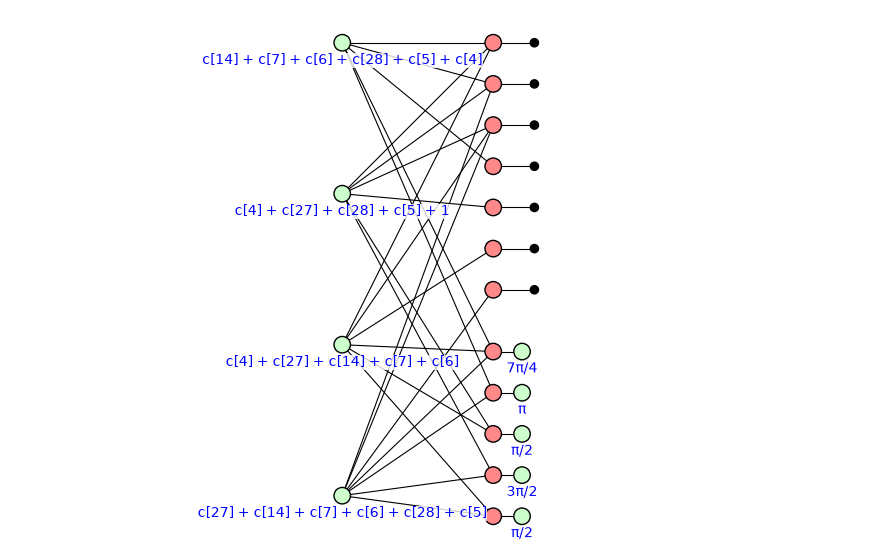

In [19]:
t0 = time.perf_counter()
sig = ef.signature(pair)
t_sig = time.perf_counter() - t0
print("1. signature (add up formulas): results flipped {}, T switches on {}, output Pauli {}; about {:.5f} s".format(
    sorted(sig[0]) or 'none', [t.name for t in ef.t_flips if t.name in sig[1]], sorted(sig[2]), t_sig))
values = {t.name: int(t.name in sig[1]) for t in ef.t_flips}
values.update({'{}{}'.format(o, q): int('{}{}'.format(o, q) in sig[2]) for q in sorted(ef.frame) for o in ('ox', 'oz')})
print("2. the values for this pair:", ' '.join('{}={}'.format(k, v) for k, v in values.items()))
print("   results flipped by this pair: {} (a flipped result c would be read as c + 1); every c[j] stays a variable".format(
    sorted(sig[0]) or 'none'))
t0 = time.perf_counter()
small = reduce_gpf(ef.reduced.to_graph().substitute_variables(values))
t_small = time.perf_counter() - t0
S = small.to_graph()
print("3. the reduced diagram with these values, reduced again: {} spiders, {} gadgets {}; about {:.3f} s".format(
    sum(1 for v in S.vertices() if S.type(v) != 0), len(phase_polynomial(S)[1]),
    [str(S.phase(ls[0])) for _h, ls in phase_polynomial(S)[1]], t_small))
print("   in it: {} green spiders that are not gadget leaves, {} outputs".format(
    sum(1 for v in S.vertices() if S.type(v) == VertexType.Z and not is_leaf(S, v)), len(S.outputs())))
t0 = time.perf_counter()
fast = ef.classify(pair)
t_fast = time.perf_counter() - t0
print("4. classify(pair) = {}: about {:.2f} s (steps 1 to 3, then the runs compared with the noiseless ones)".format(
    fast, t_fast))
t0 = time.perf_counter()
ef.classify(pair)
print("   asked again: the verdict is remembered for this signature, about {:.5f} s".format(time.perf_counter() - t0))
print("each fault alone:", {ef.describe(part): ef.classify(part) for part in ({252: 'X'}, {286: 'Y'})})
layout_gpf(S)
fig = draw_graph(S, time_axis=False, show_time=False, label_size=10, figsize=(11, 7))
fig.savefig(FIG + '/d3_pair_small.png', bbox_inches='tight')
display(fig)

**What you see.**

| step | result | time |
|---|---|---|
| 1. signature | no result flipped; `f8`, `f9`, `f11`; `ox0`, `ox3`, `ox8`, `oz8` | about 0.00006 s |
| 2. values | `f8` = `f9` = `f11` = 1, `ox0` = `ox3` = `ox8` = `oz8` = 1; every other `f`, `ox`, `oz` is 0 | - |
| 3. small diagram | 21 spiders, 5 gadgets (7π/4, π, π/2, 3π/2, π/2) | about 0.030 s |
| 4. `classify` | **wrong** | about 0.19 s |

* The 0s in step 2 are this pair's own values (Section 5): it turns those switches off. No value is a free choice.
* The pair flips no result, so every result stays a variable. (A flipped result `c` would be read as `c + 1`.)
* Asked again, the verdict is remembered: about 0.00004 s.
* Each fault alone is **caught**. Together they are **wrong**.

The picture is the small diagram: 4 green spiders on the left, 7 outputs and 5 gadgets on the right. Its phases read only results and numbers: every `f`, `ox` and `oz` has its value. (The drawing does not name the green spiders.)

**What we do.** The **slow way**, on the same pair.

* `program_with` puts the two error gates into the circuit. We draw the two stages that have them.
* `classify_directly` reduces the whole circuit with the errors in it, and gives a verdict. We time it.

the errors are in stages [3, 4]


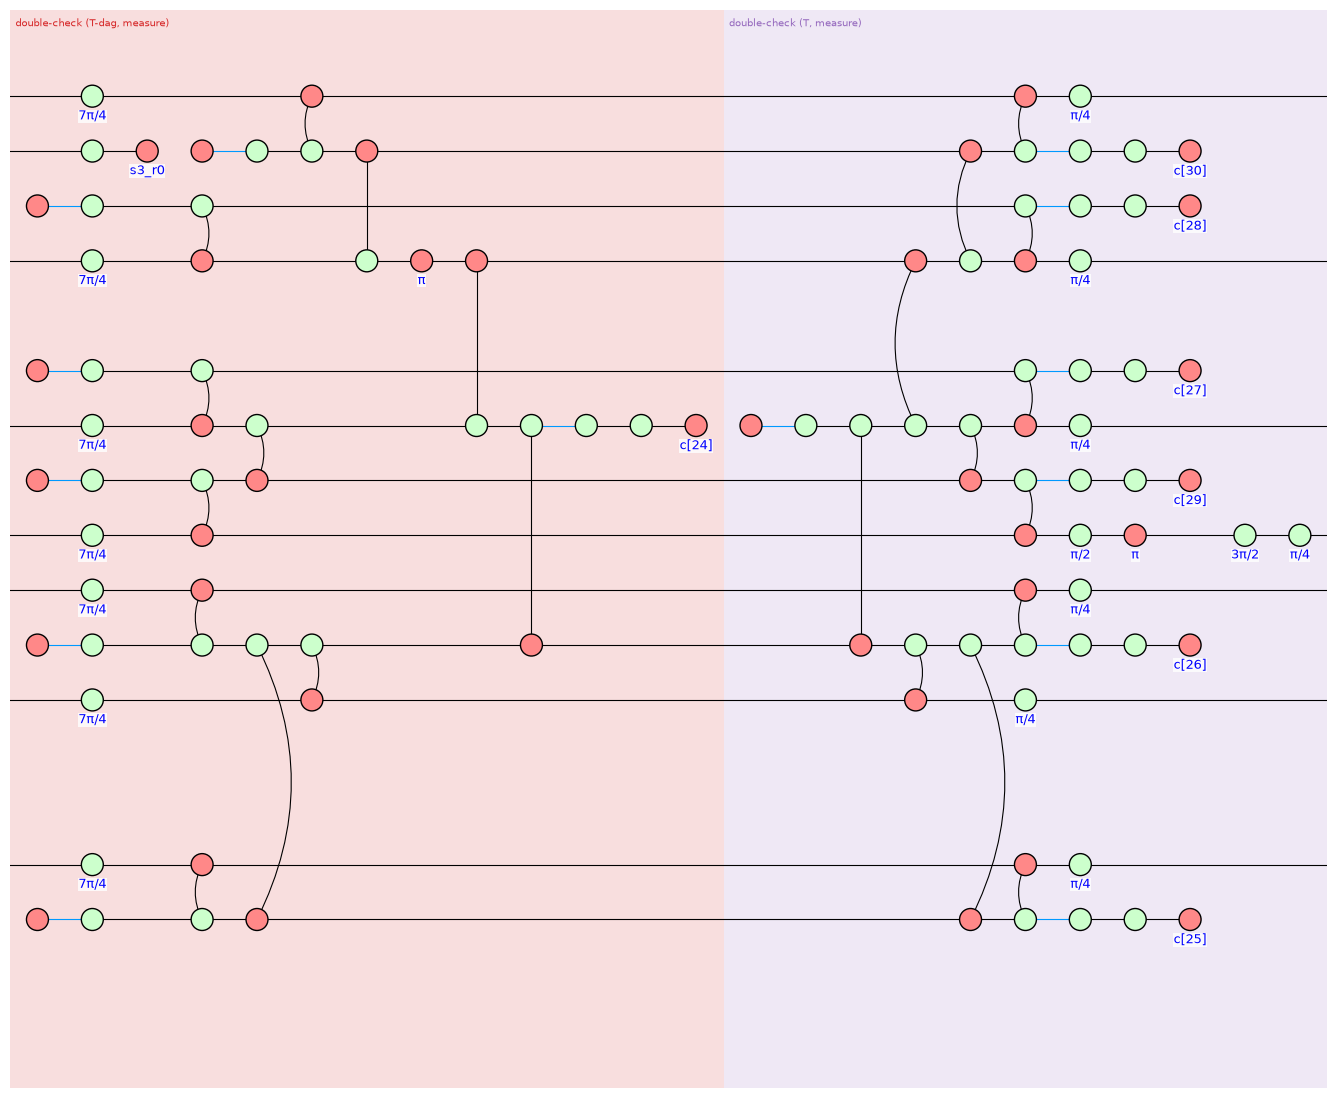

the whole circuit with the two error gates: 374 spiders
classify_directly(pair) = wrong: about 0.23 s


In [20]:
with_errors = ef.program_with(pair)
print("the errors are in stages", sorted({ef.places[k].stage for k in pair}))
fig = draw_program(with_errors, 0, time_axis=False, show_time=False, even_rows=True, labels_above=True,
                   figsize=(20, 14), blocks=[3, 4], label_size=9)
fig.savefig(FIG + '/d3_pair_slow_stages34.png', bbox_inches='tight')
display(fig)
big = with_errors.quantum_graph()
print("the whole circuit with the two error gates: {} spiders".format(sum(1 for v in big.vertices() if big.type(v) != 0)))
t0 = time.perf_counter()
slow = ef.classify_directly(pair)
t_slow = time.perf_counter() - t0
print("classify_directly(pair) = {}: about {:.2f} s".format(slow, t_slow))

**What you see.** The errors are in stages 3 and 4. The top line is qubit 0.

* The X on qubit 3 is the red π spider in stage 3 (pink), on the 4th line.
* The Y on qubit 8 is three spiders in stage 4 (purple), near the right end of one line: green π/2, red π, green 3π/2. The π/4 right after them is the T gate of qubit 8.

The whole circuit with these two error gates has 374 spiders. `classify_directly` reduces all of it: **wrong**, about 0.23 s. The same verdict as the fast way.

**What we do.** Every single fault, the fast way. `single_faults` lists them per gate:

* 3 kinds after a one-qubit gate: X, Y, Z;
* 15 kinds after a CNOT: any two-qubit Pauli except II.

We count the verdicts per kind of gate.

In [21]:
t0 = time.perf_counter()
singles = ef.single_faults()
table = Counter()
for place, kinds_at in singles:
    for f in kinds_at:
        table[place.name, ef.classify(f)] += 1
t_singles = time.perf_counter() - t0
n_single = sum(len(k) for _p, k in singles)
print("{} gates with faults; {} single faults (3 kinds after a 1-qubit gate, 15 after a CNOT)".format(len(singles), n_single))
print("after a | caught | harmless | wrong")
for gate in sorted({g for g, _v in table}):
    print("  {:5s} | {:6d} | {:8d} | {:5d}".format(gate, table[gate, 'caught'], table[gate, 'harmless'], table[gate, 'wrong']))
print("  all   | {:6d} | {:8d} | {:5d}".format(*(sum(n for (g, v), n in table.items() if v == w)
                                                for w in ('caught', 'harmless', 'wrong'))))
print("all single faults, the fast way: about {:.1f} s".format(t_singles))

200 gates with faults; 1848 single faults (3 kinds after a 1-qubit gate, 15 after a CNOT)
after a | caught | harmless | wrong
  CNOT  |   1468 |       92 |     0
  HAD   |     82 |       41 |     0
  Reset |     74 |       46 |     0
  T     |     44 |        1 |     0
  all   |   1668 |      180 |     0
all single faults, the fast way: about 11.4 s


**What you see.** 200 gates can have a fault: 1848 single faults.

| after a | caught | harmless | wrong |
|---|---|---|---|
| CNOT | 1468 | 92 | 0 |
| HAD | 82 | 41 | 0 |
| Reset | 74 | 46 | 0 |
| T | 44 | 1 | 0 |
| all | 1668 | 180 | **0** |

**No single fault is wrong.** All 1848 took about 11.4 s.

**What we do.** Every pair of faults at two different gates, the fast way: `lowest_wrong(2)`.

* It tries every single fault, then every pair.
* For each pair it adds up formulas. It gets the verdict of the signature the way `classify` does, and remembers it.

This is the slowest step of the notebook: several minutes (the time is printed below). It is the main check, so we keep it. Then we count the different signatures of all pairs, and the sets of T gates they turn around.

In [22]:
counts = [len(k) for _p, k in singles]
n_pairs = (sum(counts) ** 2 - sum(k * k for k in counts)) // 2
print("pairs of faults at two different gates:", n_pairs)
t0 = time.perf_counter()
weight, wrong = ef.lowest_wrong(2)
t_pairs = time.perf_counter() - t0
print("lowest_wrong(2): fewest faults that are wrong = {}; {} wrong pairs; about {:.0f} s, about {:.2f} ms a pair".format(
    weight, len(wrong), t_pairs, 1000 * t_pairs / n_pairs))
for p in wrong[:4]:
    print("  ", ef.describe(p), "| T switches on:", [t.name for t in ef.t_flips if t.name in ef.signature(p)[1]])
print("the example pair is one of them:", pair in wrong)
t0 = time.perf_counter()
print("the slow way (classify_directly) says wrong for all {}: {} (about {:.0f} s)".format(
    len(wrong), all(ef.classify_directly(p) == 'wrong' for p in wrong), time.perf_counter() - t0))
print("results flipped by any of them:", sorted({c for p in wrong for c in ef.signature(p)[0]}) or 'none',
      "; T switches on:", [t.name for t in ef.t_flips if any(t.name in ef.signature(p)[1] for p in wrong)])
masks = [[(ef.mask(f), ef.signature(f)[1]) for f in k] for _p, k in singles]
signatures = {}                            # the signature of a pair -> the T gates it turns around
for i in range(len(masks)):
    for j in range(i + 1, len(masks)):
        for a, ta in masks[i]:
            for b, tb in masks[j]:
                signatures[a ^ b] = ta ^ tb
turned = [t for t in signatures.values() if t]
print("the {} pairs have {} different signatures:".format(n_pairs, len(signatures)))
print("  {} turn T gates around; they turn around only {} different sets of T gates".format(len(turned), len(set(turned))))
print("  {} turn no T gate around".format(len(signatures) - len(turned)))

pairs of faults at two different gates: 1695420


lowest_wrong(2): fewest faults that are wrong = 2; 48 wrong pairs; about 503 s, about 0.30 ms a pair
   X on qubit 3 after the CNOT (stage 3, gate 25); Y on qubit 8 after the CNOT (stage 4, gate 11) | T switches on: ['f8', 'f9', 'f11']
   X on qubit 3 after the CNOT (stage 3, gate 25); X on qubit 7, Y on qubit 8 after the CNOT (stage 4, gate 11) | T switches on: ['f8', 'f9', 'f11']
   X on qubit 3 after the CNOT (stage 3, gate 25); X on qubit 8 after the T (stage 4, gate 17) | T switches on: ['f8', 'f9']
   X on qubit 3 after the CNOT (stage 3, gate 25); Y on qubit 8 after the T (stage 4, gate 17) | T switches on: ['f8', 'f9']
the example pair is one of them: True


the slow way (classify_directly) says wrong for all 48: True (about 11 s)
results flipped by any of them: none ; T switches on: ['f8', 'f9', 'f10', 'f11', 'f12', 'f13', 'f14']


the 1695420 pairs have 232487 different signatures:
  212796 turn T gates around; they turn around only 575 different sets of T gates
  19691 turn no T gate around


**What you see.** There are 1695420 pairs. `lowest_wrong(2)` tried them all in about 503 s, about 0.30 ms a pair.

* **2 faults are enough**: 48 pairs are wrong.
* The example pair is one of them.
* The slow way (`classify_directly`) says wrong for all 48 too.
* None of the 48 flips a result.
* They turn on T switches of stage 4 only (`f8` to `f14`).

Why it is fast:

* The 1695420 pairs have only 232487 different signatures. `classify` decides each one at most once, and remembers it.
* 212796 of these signatures turn T gates around, but they turn around only 575 different sets of T gates. For each set, `classify` reduces one diagram, once. Its checks can then catch a signature of that set by adding up, with no new diagram.
* The other 19691 signatures turn no T gate around. When one of them fires a check, adding up shows it.
* Only a signature that none of this catches gets a small diagram of its own.

**What we do.** The slow way for all pairs would take too long. So we time it on 30 random pairs, and multiply.

A random pair here: two different gates, drawn at random (seed 7), then a random fault at each gate. This is not exactly a fair draw from all pairs.

Then we put both ways side by side.

In [23]:
rng = random.Random(7)
sample = []
while len(sample) < 30:
    a, b = rng.sample(range(len(singles)), 2)
    sample.append({**rng.choice(singles[a][1]), **rng.choice(singles[b][1])})
t0 = time.perf_counter()
slow_verdicts = [ef.classify_directly(e) for e in sample]
per_pair = (time.perf_counter() - t0) / len(sample)
print("the slow way on 30 random pairs (seed 7): about {:.2f} s a pair; verdicts {}".format(per_pair, dict(Counter(slow_verdicts))))
print("the same verdicts as the fast way:", slow_verdicts == [ef.classify(e) for e in sample])
print("estimate for all {} pairs, the slow way: about {:.0f} hours (the fast way took about {:.0f} s)".format(
    n_pairs, per_pair * n_pairs / 3600, t_pairs))
print()
row = "{:18s} | {:80s} | {}"
print(row.format("", "fast way (formulas, then a small diagram)", "slow way (the whole circuit)"))
print(row.format("what is reduced", "once: the circuit with f, ox, oz as variables ({} spiders left)".format(
    sum(1 for v in reduced.vertices() if reduced.type(v) != 0)), "the circuit with the error gates ({} spiders)".format(
    sum(1 for v in big.vertices() if big.type(v) != 0))))
print(row.format("how often", "then a small diagram at most once per signature, when needed", "once per pattern"))
print(row.format("the example pair", "signature about {:.5f} s; small diagram about {:.3f} s; verdict about {:.2f} s".format(
    t_sig, t_small, t_fast), "verdict about {:.2f} s".format(t_slow)))
print(row.format("all {} pairs".format(n_pairs), "about {:.0f} s, about {:.2f} ms a pair".format(
    t_pairs, 1000 * t_pairs / n_pairs), "about {:.0f} hours (estimate)".format(per_pair * n_pairs / 3600)))

the slow way on 30 random pairs (seed 7): about 0.08 s a pair; verdicts {'caught': 28, 'harmless': 2}
the same verdicts as the fast way: True
estimate for all 1695420 pairs, the slow way: about 39 hours (the fast way took about 503 s)

                   | fast way (formulas, then a small diagram)                                        | slow way (the whole circuit)
what is reduced    | once: the circuit with f, ox, oz as variables (43 spiders left)                  | the circuit with the error gates (374 spiders)
how often          | then a small diagram at most once per signature, when needed                     | once per pattern
the example pair   | signature about 0.00006 s; small diagram about 0.030 s; verdict about 0.19 s     | verdict about 0.23 s
all 1695420 pairs  | about 503 s, about 0.30 ms a pair                                                | about 39 hours (estimate)


**What you see.** On the 30 random pairs the slow way takes about 0.08 s a pair. Its verdicts (28 caught, 2 harmless) are the same as the fast way's. For all 1695420 pairs that is about 39 hours. The fast way took about 503 s.

| | fast way | slow way |
|---|---|---|
| what is reduced | once: the circuit with `f`, `ox`, `oz` as variables (43 spiders left); then a small diagram at most once per signature, when needed | the circuit with the error gates (374 spiders), once per pattern |
| the example pair | verdict about 0.19 s | verdict about 0.23 s |
| all 1695420 pairs | about 503 s (about 0.30 ms a pair) | about 39 hours (estimate) |

For **one** new pair the two ways cost about the same. The gain comes from the many pairs:

* a signature is a sum of formulas (about 0.00006 s);
* many pairs share a signature, and each signature is decided at most once;
* signatures that turn the same T gates around share one reduced diagram (575 sets);
* a small diagram of its own comes only when needed.

## 7. A solver: fault distance, witness, every wrong signature

**What we do.** A solver can find a wrong pattern without trying every pair.

* A flipped T gate adds an $S^\dagger$ (an S for a flipped $T^\dagger$). An $S^\dagger$ is a sum of I and Z. So a pattern splits into *branches*. Each branch is a Pauli error.
* If no branch is wrong, the pattern is not wrong either. So a wrong pattern has a wrong branch. This is the *branch argument*. The docstring of `fault_search` calls it argued, not proved.
* `branch_model` writes the question "this branch passes every check and changes the logical state" as rows over the bits of a signature.

We use a fresh copy of the formulas (`error_formulas` again), so that no verdict from Section 6 is remembered.

In [24]:
ef2 = error_formulas(real)                 # a fresh copy: no verdict remembered from Section 6
model = branch_model(ef2)
print(model.describe())
print("wrong kind:", model.wrong_kind)

Output code: [[7, 1]] on qubits 0, 3, 6, 8, 9, 11, 14.
Checks: 26 detectors of the noiseless program, 6 final-check rows (one per stabilizer).
Logical rows: the X row also reads the results c[4] + c[5] + c[6] + c[7] + c[14]; the Z row reads none.
Wrong logical errors: X, Y, Z (none is harmless).
T gates: 15 (a Z right after each flips no T gate).
Fault choices: 740 from 1745 fault kinds (one per signature, per gate); 103 kinds with an empty signature dropped.
Self-check: 48 random Pauli patterns agree with classify (35 caught, 4 harmless, 9 wrong); 23 probes learned the logical rows.
Built in 7.0 s.
wrong kind: any


**What you see.** The model, in its own words:

* the output code is the [[7,1]] code on the 7 output qubits;
* 26 rows for the checks of the circuit, 6 rows for the final check (one per stabilizer of the code);
* the logical X row also reads `c[4] + c[5] + c[6] + c[7] + c[14]`: the logical Z correction of Section 2;
* every logical error is wrong (X, Y and Z): wrong kind `any`;
* 15 T gates;
* 740 fault choices from 1745 fault kinds: faults at one gate with the same signature are one choice. 103 fault kinds have an empty signature (they change nothing) and are dropped;
* self-check: on 48 random Pauli patterns the rows agree with `classify`.

It was built in about 7.0 s.

**What we do.** `search_lowest_wrong`. It works in a loop:

1. the solver proposes the lightest pattern that has a wrong branch (at most one fault per gate);
2. `classify` decides it, with the diagram;
3. if it is not wrong, the solver is told to skip it (a *cut*), and runs again.

We choose two settings:

| setting | what it does |
|---|---|
| `solver='sat'` | a SAT solver (CaDiCaL, from the package python-sat). It keeps what it learned from one solve to the next. |
| `cut='coset'` | skip the whole *class* of the pattern, not only its signature (a *class cut*). A class: every signature with the same flipped T gates and the same value on every check row, final-check row and logical row (`model.coset`). A class has one verdict (the docstring of `fault_search` says why). |

With `cut='coset'` there is one more cut: the first time a set of flipped T gates comes up, every signature that one of its checks catches is skipped.

Why these two settings:

* The docstring of `fault_search` says that a SAT solve was faster than a CP-SAT solve (on the d = 5 circuit). It also says that CP-SAT (the default solver) is slow with class cuts.
* In a timing run before this notebook, sat with class cuts was the fastest way to list every wrong signature (the cell with `all_wrong=True`, below).
* This notebook does not time the other settings.

`log=print` prints every solve. Then we print what the solver gives:

* the fault distance: the fewest faults that are wrong;
* a *witness*: which faults, after which gate, on which qubit;
* why it is wrong: its signature (T switches turned on, results flipped, Pauli left on the outputs);
* the verdicts of `classify` and `classify_directly`, and whether it is one of the 48 wrong pairs of Section 6.

In [25]:
result = search_lowest_wrong(ef2, 3, solver='sat', cut='coset', model=model, log=print)
print()
print(result.describe())
tally = Counter((s.weight, c.verdict) for s in result.solves for c in s.candidates)
print("verdicts per weight:", '; '.join('weight {}: {}'.format(w, ', '.join(
    '{} {}'.format(tally[w, v], v) for v in ('harmless', 'caught', 'wrong') if tally[w, v])) for w in sorted({w for w, _v in tally})))
print("first solve: weight", result.solves[0].weight, "; rejected per weight:", result.rejected_per_weight,
      "; ruled out:", result.ruled_out)
print("the pattern found:", result.pattern, "; the example pair of Section 5:", result.pattern == pair)
found = ef2.signature(result.pattern)
print("why it is wrong (its signature): T switches on {}; output Pauli {}; results flipped {}".format(
    [t.name for t in ef2.t_flips if t.name in found[1]],
    ['{}{}'.format(o, q) for q in sorted(ef2.frame) for o in ('ox', 'oz') if '{}{}'.format(o, q) in found[2]],
    sorted(found[0]) or 'none'))
print("classify:", ef2.classify(result.pattern), "; classify_directly:", ef2.classify_directly(result.pattern),
      "; one of the 48 wrong pairs of Section 6:", result.pattern in wrong)

solve 1: weight 1 (0.01 s); harmless [7 T flips] (0.11 s)


solve 2: weight 1 (0.05 s); harmless [7 T flips] (0.12 s)


solve 3: weight 1 (0.02 s); harmless [7 T flips] (0.11 s)
solve 4: weight 1 (0.01 s); harmless [7 T flips] (0.11 s)


solve 5: weight 1 (0.00 s); harmless [7 T flips] (0.11 s)


solve 6: weight 2 (0.27 s); harmless [6 T flips] (0.05 s)
solve 7: weight 2 (0.64 s); harmless [8 T flips] (0.05 s)
solve 8: weight 2 (0.16 s); harmless [8 T flips] (0.05 s)
solve 9: weight 2 (0.12 s); harmless [8 T flips] (0.04 s)


solve 10: weight 2 (0.07 s); caught [6 T flips] (0.03 s)
solve 11: weight 2 (0.18 s); harmless [8 T flips] (0.06 s)
solve 12: weight 2 (0.06 s); harmless [6 T flips] (0.03 s)
solve 13: weight 2 (0.01 s); harmless [8 T flips] (0.03 s)


... (2 outputs left out)

solve 20: weight 2 (0.01 s); harmless [6 T flips] (0.08 s)
solve 21: weight 2 (0.01 s); caught [7 T flips] (0.08 s)
solve 22: weight 2 (0.00 s); caught [8 T flips] (0.04 s)
solve 23: weight 2 (0.00 s); caught [8 T flips] (0.03 s)
solve 24: weight 2 (0.01 s); caught [8 T flips] (0.02 s)
solve 25: weight 2 (0.00 s); caught [8 T flips] (0.10 s)


solve 26: weight 2 (0.00 s); harmless [7 T flips] (0.12 s)
solve 27: weight 2 (0.04 s); caught [7 T flips] (0.08 s)
solve 28: weight 2 (0.02 s); harmless [4 T flips] (0.09 s)


solve 29: weight 2 (0.00 s); harmless [4 T flips] (0.09 s)
solve 30: weight 2 (0.01 s); wrong [3 T flips] (0.11 s)
done: weight 2, finished True, at least 2 faults, 29 rejected, 1 wrong, 433 check cuts, 4.5 s

2 faults are wrong: X on qubit 3 after the CNOT (stage 3, gate 25); Y on qubit 8 after the CNOT (stage 4, gate 11). No pattern of 1 fault is wrong.
30 solves (sat, coset cuts, 433 from checks), 29 candidates rejected (5 at weight 1, 24 at weight 2); model 0.0 s, solver 2.1 s, classify 2.3 s, total 4.5 s.
verdicts per weight: weight 1: 5 harmless; weight 2: 13 harmless, 11 caught, 1 wrong
first solve: weight 1 ; rejected per weight: {1: 5, 2: 24} ; ruled out: [1]
the pattern found: {252: 'X', 286: 'Y'} ; the example pair of Section 5: True
why it is wrong (its signature): T switches on ['f8', 'f9', 'f11']; output Pauli ['ox0', 'ox3', 'ox8', 'oz8']; results flipped none


classify: wrong ; classify_directly: wrong ; one of the 48 wrong pairs of Section 6: True


**What you see.** 30 solves, about 4.5 s in all (the model was built in the cell above).

| solves | weight | what `classify` says |
|---|---|---|
| 1 to 5 | 1 | harmless (each turns 7 T gates around): rejected |
| the next 24 | 2 | 13 harmless, 11 caught: rejected |
| the last one | 2 | **wrong** |

Besides the class cuts, 433 cuts came from checks (signatures that a check catches, skipped at once).

What the solver gives:

| what | here |
|---|---|
| fault distance | **2** |
| witness | X on qubit 3 after a CNOT (stage 3, gate 25), and Y on qubit 8 after a CNOT (stage 4, gate 11). This is the example pair of Section 5 (True). |
| why it is wrong | it turns on `f8`, `f9`, `f11`; it flips no result; it leaves `ox0`, `ox3`, `ox8`, `oz8`: X on qubits 0 and 3, Y on qubit 8 |
| checked | `classify`: wrong. `classify_directly`: wrong. One of the 48 wrong pairs of Section 6: True. |

1 fault is ruled out by three things: the branch argument, the class cut, and the solver. After 5 solves the solver found nothing more with 1 fault. These 5 solves stood for 8 signatures (next cell). Section 6 checks this by trying every single fault.

**What we do.** Why did the first solves give 1 fault? We ask the rows about every single fault: which ones have a branch that the rows call wrong (`wrong_branch`)? We count their signatures, and their classes (`model.coset`). Then `classify` decides them.

We also check that each of the 48 wrong pairs has a wrong branch. The search needs this.

In [26]:
maybe = [f for _p, kinds_at in ef2.single_faults() for f in kinds_at if model.wrong_branch(ef2.mask(f)) is not None]
print(len(maybe), "single faults have a branch that the rows call wrong;", len({ef2.mask(f) for f in maybe}),
      "different signatures, in", len({model.coset(ef2.mask(f)) for f in maybe}), "classes; classify:",
      dict(Counter(ef2.classify(f) for f in maybe)))
print("all {} wrong pairs of Section 6 have a wrong branch: {}".format(
    len(wrong), all(model.wrong_branch(ef2.mask(p)) is not None for p in wrong)))

49

 single faults have a branch that the rows call wrong; 8 different signatures, in 5 classes; classify: {'harmless': 49}
all 48 wrong pairs of Section 6 have a wrong branch: True


**What you see.** 49 single faults have a branch that the rows call wrong. They have 8 different signatures, in only 5 classes. A class cut skips a whole class. So the solver needed 5 solves at weight 1: one per class. `classify` says all 49 are harmless. So the diagram rules them out; the rows alone cannot.

All 48 wrong pairs have a wrong branch, as the search needs.

**What we do.** The solver can also list **every** wrong signature, not only one witness. With `all_wrong=True`:

* the search does not stop at the first wrong pattern. It goes on, up to 2 faults;
* a wrong signature is skipped by itself only. So the other wrong signatures of its class are found too;
* `batch=4`: each solve asks for up to 4 patterns of the lightest weight, from different classes. Then `classify` decides them.

We take a fresh copy of the formulas and a fresh model. So no verdict from above is remembered, and the time is fair.

`log=solve_log.append` keeps every solve in a list. We print how many solves there were, and the last two lines. Then:

* each wrong signature: the T switches it turns on, the Pauli it leaves on the outputs, the results it flips, and one pattern with it;
* one line that sums them all up ("all of them");
* the slow way (`classify_directly`) on each of these patterns;
* the signatures of Section 6's 48 wrong pairs (`ef.signature`), to compare;
* the time, next to the time of `lowest_wrong(2)` in Section 6.

In [27]:
ef3 = error_formulas(real)                 # a fresh copy again: no verdict remembered, so the time is fair
model3 = branch_model(ef3)
print("a fresh model, built in about {:.1f} s".format(model3.seconds))
solve_log = []
every_wrong = search_lowest_wrong(ef3, 2, solver='sat', cut='coset', batch=4, all_wrong=True, model=model3,
                                  log=solve_log.append)
print(len(every_wrong.solves), "solves (one line each in solve_log); the last two lines of the log:")
for line in solve_log[-2:]:
    print("   ", line)
print(every_wrong.describe())
tally_all = Counter((s.weight, c.verdict) for s in every_wrong.solves for c in s.candidates)
print("verdicts per weight:", '; '.join('weight {}: {}'.format(w, ', '.join(
    '{} {}'.format(tally_all[w, v], v) for v in ('harmless', 'caught', 'wrong') if tally_all[w, v]))
    for w in sorted({w for w, _v in tally_all})))
print()
print(len(every_wrong.wrong), "wrong signatures listed:")
print("  T switches on       | output Pauli                 | results flipped | one pattern with it")
for c in every_wrong.wrong:
    print("  {:19s} | {:28s} | {:15s} | {}".format(
        ' '.join(t.name for t in ef3.t_flips if t.name in c.signature[1]),
        ' '.join('{}{}'.format(o, q) for q in sorted(ef3.frame) for o in ('ox', 'oz') if '{}{}'.format(o, q) in c.signature[2]),
        ' '.join(sorted(c.signature[0])) or 'none', c.pattern))
n_t = sorted({len(c.signature[1]) for c in every_wrong.wrong})
n_x = sorted({sum(x[:2] == 'ox' for x in c.signature[2]) for c in every_wrong.wrong})
stages = sorted({t.stage for t in ef3.t_flips if any(t.name in c.signature[1] for c in every_wrong.wrong)})
print("all of them: {} to {} T switches on, all in stage {}; X on {} output qubits; a Z part too in {} of {}".format(
    n_t[0], n_t[-1], ' and '.join(str(s) for s in stages), ' or '.join(str(n) for n in n_x),
    sum(any(x[:2] == 'oz' for x in c.signature[2]) for c in every_wrong.wrong), len(every_wrong.wrong)))
print("classify_directly on these {} patterns: {}".format(
    len(every_wrong.wrong), dict(Counter(ef3.classify_directly(c.pattern) for c in every_wrong.wrong))))
print()
by_signature = Counter(ef.signature(p) for p in wrong)
print("Section 6: the {} wrong pairs have {} signatures; pairs per signature: {}".format(
    len(wrong), len(by_signature), sorted(by_signature.values())))
print("the same signatures as listed here:", set(by_signature) == {c.signature for c in every_wrong.wrong})
print("time: this search about {:.1f} s, plus about {:.1f} s for its model; lowest_wrong(2) in Section 6 about {:.0f} s".format(
    every_wrong.total_seconds, model3.seconds, t_pairs))

a fresh model, built in about 5.2 s


25 solves (one line each in solve_log); the last two lines of the log:
    solve 25: nothing left up to 2 faults (0.01 s)
    done: weight 2, finished True, at least 2 faults, 78 rejected, 12 wrong, 741 check cuts, 9.7 s
2 faults are wrong: X on qubit 6 after the CNOT (stage 4, gate 3); X on qubit 9 after the T (stage 4, gate 18). No pattern of 1 fault is wrong. 12 wrong signatures listed.
25 solves (sat, batch 4, coset cuts, 741 from checks), 78 candidates rejected (5 at weight 1, 73 at weight 2); model 0.0 s, solver 2.8 s, classify 6.9 s, total 9.7 s.
verdicts per weight: weight 1: 5 harmless; weight 2: 38 harmless, 35 caught, 12 wrong

12 wrong signatures listed:
  T switches on       | output Pauli                 | results flipped | one pattern with it
  f10 f11             | ox6 ox8 ox9                  | none            | {269: 'X', 295: 'X'}
  f10 f11             | ox6 ox8 ox9 oz9              | none            | {269: 'X', 295: 'Y'}
  f10 f11 f12         | ox6 ox8 ox9 oz9     

classify_directly on these 12 patterns: {'wrong': 12}

Section 6: the 48 wrong pairs have 12 signatures; pairs per signature: [2, 2, 2, 2, 4, 4, 4, 4, 4, 4, 8, 8]
the same signatures as listed here: True
time: this search about 9.7 s, plus about 5.2 s for its model; lowest_wrong(2) in Section 6 about 503 s


**What you see.** 25 solves. The last one finds nothing left up to 2 faults: the list is complete (up to the argument below). 78 proposed patterns were not wrong.

The first line of `describe()` names the first wrong pair this search found: X on qubit 6 after a CNOT and X on qubit 9 after a T, both in stage 4. It is another witness, not the pair of Section 5. Each of the 12 rows of the table is a witness.

The 12 wrong signatures (the line "all of them" sums them up):

* none of them flips a result;
* they turn on 2 to 5 T switches, all in stage 4 (`f8` to `f14`);
* the Pauli left on the outputs has an X part on 3 or 4 qubits; 8 of the 12 also have a Z part;
* `classify_directly` says wrong for all 12.

Compared with Section 6:

| | wrong signatures | wrong pairs |
|---|---|---|
| `lowest_wrong(2)`: every pair (Section 6) | 12 | 48: 2, 4 or 8 for each signature |
| `search_lowest_wrong(..., all_wrong=True)` | the same 12 (True) | one pair is shown for each |

Pairs with one signature give every formula the same value. So `classify` gives them one verdict. That is why one pair for each signature is enough.

| | time |
|---|---|
| this search | about 9.7 s, plus about 5.2 s for its model |
| trying every pair (`lowest_wrong(2)`, Section 6) | about 503 s |

* **Certified:** each of the 12 is wrong by `classify` and by `classify_directly`. And they are exactly the signatures of the 48 wrong pairs that Section 6 found by trying every pair.
* **Argued:** that the solver's list is complete on its own. This rests on the branch argument, the class cut, and the solver's last answer: nothing left. Here, Section 6 confirms it.

**What we do.** The same question, with S in place of T.

* zxqec's `circuit_distance` writes the circuit for Stim. Stim turns it into an error model. Then the package codedistance finds the fewest faults, with a solver (MIP).
* This works only for circuits without T gates. We first give it the real circuit: it should refuse. Then we give it the S version.
* The end state of the S version is a stabilizer state. So the code read from it has no logical qubit (printed). We give the real circuit's code instead, as the code to check against (`code_out`).
* Then `search_lowest_wrong` on the S version, with the same settings (`solver='sat'`, `cut='coset'`), up to 3 faults.

In [28]:
try:
    circuit_distance(real)
except NotCliffordError as e:
    print("circuit_distance on the real circuit:", e)
with_s = program_from_stim(text.replace('T_DAG ', 'S_DAG ').replace('\nT ', '\nS '), names=names)[0]
print("the S version: the code at its end has", with_s.code_at(with_s.num_stages - 1).k, "logical qubits")
t0 = time.perf_counter()
stim = circuit_distance(with_s, code_out=code)
print("circuit_distance with S in place of T:", stim, "(about {:.0f} s)".format(time.perf_counter() - t0))
ef_s = error_formulas(with_s, code_out=colour_code)
model_s = branch_model(ef_s, code_out=colour_code)
print(model_s.describe())
print("wrong kind:", model_s.wrong_kind)
result_s = search_lowest_wrong(ef_s, 3, code_out=colour_code, solver='sat', cut='coset', model=model_s, log=print)
print(result_s.describe())
print("classify:", ef_s.classify(result_s.pattern), "; classify_directly:", ef_s.classify_directly(result_s.pattern))

circuit_distance on the real circuit: stage 1: T*(13) is not a Clifford gate this function supports
the S version: the code at its end has 0 logical qubits


circuit_distance with S in place of T: full circuit distance of stages 0-4: 3 (- -> Y: 3) (about 1 s)


Output code: [[7, 1]] on qubits 0, 3, 6, 8, 9, 11, 14.
Checks: 26 detectors of the noiseless program, 6 final-check rows (one per stabilizer).
Logical rows: the X row also reads the results c[4] + c[5]; the Z row reads c[6] + c[7] + c[14].
Wrong logical errors: X, Z (Y is harmless).
T gates: 0 (a Z right after each flips no T gate).
Fault choices: 704 from 1744 fault kinds (one per signature, per gate); 104 kinds with an empty signature dropped.
Self-check: 48 random Pauli patterns agree with classify (35 caught, 8 harmless, 5 wrong); 23 probes learned the logical rows.
Built in 5.7 s.
wrong kind: xor


solve 1: weight 3 (2.41 s); wrong [0 T flips] (0.08 s)
done: weight 3, finished True, at least 3 faults, 0 rejected, 1 wrong, 0 check cuts, 2.5 s
3 faults are wrong: Z on qubit 0 after the CNOT (stage 2, gate 12); Y on qubit 10, Z on qubit 11 after the CNOT (stage 3, gate 29); Y on qubit 6 after the CNOT (stage 4, gate 10). No pattern of at most 2 faults is wrong.
1 solves (sat, coset cuts, 0 from checks), 0 candidates rejected; model 0.0 s, solver 2.4 s, classify 0.1 s, total 2.5 s.
classify: wrong ; classify_directly: wrong


**What you see.**

* `circuit_distance` refuses the real circuit: "T*(13) is not a Clifford gate this function supports". `T*(13)` is the $T^\dagger$ on qubit 13. This message comes from zxqec, before Stim runs.
* The code at the end of the S version has 0 logical qubits, as said above. So we give `code_out`.
* With S in place of T, `circuit_distance` finds 3 (about 1 s).
* In `(- -> Y: 3)`, `-` means: no logical qubit at the start. `Y` means: Stim checks the logical Y at the end. In the S version only Y has a fixed value; X and Z are random, so `circuit_distance` leaves them out. 3 is the fewest faults that flip the logical Y and fire no check.
* Our model of the S version: no T gates, and Y is harmless here (wrong kind `xor`: only X and Z are wrong).
* One solve, about 3 s: **3 faults**, after three CNOTs in stages 2, 3 and 4. `classify` and `classify_directly` both say wrong. The first pattern the solver proposed was already wrong, so no cut was needed.

So with S in place of T the answer is 3. With real T gates it is 2.

**What we do.** All answers side by side.

In [29]:
print("fewest faults that are wrong | the circuit     | answer | how")
print("circuit_distance             | S in place of T | {:6} | Stim error model + codedistance MIP, Clifford only".format(
    stim.distance))
print("solver alone (first solve)   | real T          | {:6} | the rows, before classify says harmless".format(
    result.solves[0].weight))
print("solver + diagram             | real T          | {:6} | search_lowest_wrong (sat, coset), {} solves, about {:.0f} s".format(
    result.weight, len(result.solves), result.total_seconds))
print("all wrong signatures, solver | real T          | {:6} | all_wrong=True: {} signatures, {} solves, about {:.0f} s".format(
    every_wrong.weight, len(every_wrong.wrong), len(every_wrong.solves), every_wrong.total_seconds))
print("every pattern up to 2 faults | real T          | {:6} | lowest_wrong(2): {} wrong pairs, about {:.0f} s".format(
    weight, len(wrong), t_pairs))
print("solver + diagram             | S in place of T | {:6} | search_lowest_wrong (sat, coset), {} solve(s), about {:.0f} s".format(
    result_s.weight, len(result_s.solves), result_s.total_seconds))

fewest faults that are wrong | the circuit     | answer | how
circuit_distance             | S in place of T |      3 | Stim error model + codedistance MIP, Clifford only
solver alone (first solve)   | real T          |      1 | the rows, before classify says harmless
solver + diagram             | real T          |      2 | search_lowest_wrong (sat, coset), 30 solves, about 5 s
all wrong signatures, solver | real T          |      2 | all_wrong=True: 12 signatures, 25 solves, about 10 s
every pattern up to 2 faults | real T          |      2 | lowest_wrong(2): 48 wrong pairs, about 503 s
solver + diagram             | S in place of T |      3 | search_lowest_wrong (sat, coset), 1 solve(s), about 3 s


**What you see.**

| method | circuit | answer | time |
|---|---|---|---|
| `circuit_distance` (Stim error model, then codedistance) | S in place of T | 3 | about 1 s |
| solver alone (first solve) | real T | 1 | - |
| solver + diagram (`sat`, `coset`) | real T | **2** | about 5 s |
| all wrong signatures: solver + diagram, `all_wrong=True` | real T | **2**; 12 signatures | about 10 s |
| every pattern up to 2 faults, `lowest_wrong(2)` | real T | **2**; 48 pairs | about 503 s |
| solver + diagram (`sat`, `coset`) | S in place of T | 3 | about 3 s |

The solver times do not count building its model (about 7.0 s for the first one; the others are printed above).

**What is certified, and what rests on an argument.**

| claim | how | status |
|---|---|---|
| the witness pair is wrong | `classify` and `classify_directly` | certified |
| the 12 listed signatures are wrong | `classify` and `classify_directly` | certified |
| no single fault is wrong | Section 6 tries all 1848 | certified |
| 48 wrong pairs, with these 12 signatures | Section 6 tries every pair | certified |
| the solver alone misses no lighter wrong pattern, and no wrong signature | three things (below) | argued; Section 6 confirms it here |
| S in place of T: 3 | the pattern: `classify` and `classify_directly`; nothing lighter: the solver, and `circuit_distance` (another method) also says 3 | the pattern: certified; nothing lighter: two methods agree |

The argued row rests on three things:

* the *branch argument*: a wrong pattern has a wrong branch. The library calls it argued, not proved.
* the *class cut*: a class has one verdict. The docstring of `fault_search` argues this.
* the solver's answer "nothing left".

## 8. What zxqec does here

1. **Real T gates, and the code read from the diagram.** The diagram keeps every T gate. The code after each stage and the 26 checks come from the diagram. The faces are X checks of that code; the qubit coordinates in the Stim file (`circ.coords`) choose them and place the qubits. `circuit_distance`, which uses Stim, needs S in place of T, and then answers 3, not 2.
2. **Formulas, then a diagram when needed.** The switches are pushed to the end with Pauli rules: this gives the formulas. One reduction keeps the 15 T switches and the output Pauli as variables. A pattern of faults is then decided by adding up formulas, plus a small diagram when needed. The circuit is not run again for each pattern.
3. **Each step is checked.** The diagram on the code's layout is the same map as the circuit (32 of 32 runs). The diagram with every variable is the same map as `ef.reduced` (30 of 30 random values that give a map that is not zero). Here "the same map" means equal up to a number that is not zero, in each run. Every wrong pattern is confirmed the slow way.
4. **Solver and diagram together.** The solver proposes, the diagram decides. It gives the fault distance, a witness, and why the witness is wrong, in about 5 s (plus about 7.0 s for the model). With `all_wrong=True` it lists all 12 wrong signatures in about 10 s. They are the signatures of the 48 wrong pairs. Trying every pair takes about 503 s. "Nothing lighter, nothing missing" rests on the branch argument, the class cut, and the solver's answer "nothing left". Trying every pair checks it here.

**Not only zxqec.** SyQMA also finds fault distances of circuits with T gates, but it needs the code as input. Tsim also reduces a diagram once and reuses it for every Pauli error.

| question | answer | function |
|---|---|---|
| T gates, without faults | 15 gadgets add up to one $T^\dagger$ on L | `reduce_gpf` |
| checks | 26, the same as the file's | `check_detectors` |
| single faults | 1848, none wrong | `classify` |
| pairs of faults | 1695420, of which 48 wrong | `lowest_wrong(2)` |
| fault distance, real T | 2, with a witness pair | `search_lowest_wrong` (sat, coset), `lowest_wrong` |
| every wrong signature, real T | 12, the signatures of the 48 wrong pairs | `search_lowest_wrong(..., all_wrong=True)`, `lowest_wrong(2)` |
| fault distance, S in place of T | 3 | `circuit_distance` (Stim, codedistance), `search_lowest_wrong` |

**What we do.** The total time of this notebook, and how busy the machine was at the end.

In [30]:
print("total time of this notebook: about {:.0f} s".format(time.perf_counter() - start))
print("load average now (last 1, 5, 15 minutes): {:.1f}, {:.1f}, {:.1f}, on {} cores".format(*os.getloadavg(), os.cpu_count()))

total time of this notebook: about 600 s
load average now (last 1, 5, 15 minutes): 7.0, 6.3, 6.3, on 10 cores


**What you see.** The whole notebook ran in about 600 s. Most of it is the search over all pairs in Section 6 (about 503 s). The load over the last 15 minutes was about 6.3, on 10 cores: other programs ran at the same time (among them a long d = 5 run), so the times here are longer than on a quiet machine.